# Traffic Sign Classification and Robustness Evaluation
**GTSRB | CNN vs. YOLO Classification**

## 1. Data Acquisition and Preprocessing


Install Libraries & Download GTSRB

In [1]:
!pip -q install kagglehub

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

SEED = 42
IMAGE_SIZE = (128, 128)
NUM_CLASSES = 43
READY_ROOT = Path("/content/gtsrb_ready")

source_dir = Path(kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
))

roots = [
    p.parent for p in source_dir.rglob("Train.csv")
    if (p.parent / "Test.csv").is_file()
]

if len(roots) != 1:
    raise RuntimeError(
        f"Expected one GTSRB dataset root; found {len(roots)}"
    )

DATA_ROOT = roots[0].resolve()
print("Dataset location:", DATA_ROOT)


100%|██████████| 612M/612M [00:30<00:00, 21.3MB/s]

Extracting files...


Dataset location: /root/.cache/kagglehub/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/versions/1


Read Annotations & Validate Labels

In [2]:

def load_annotations(csv_name):
    df = pd.read_csv(DATA_ROOT / csv_name)

    required = {"Path", "ClassId"}
    if not required.issubset(df.columns):
        raise ValueError(
            f"Missing columns in {csv_name}: "
            f"{required - set(df.columns)}"
        )

    if df[["Path", "ClassId"]].isna().any().any():
        raise ValueError(f"Missing paths or labels in {csv_name}")

    labels = pd.to_numeric(df["ClassId"], errors="raise")

    if not labels.between(0, NUM_CLASSES - 1).all() \
       or not (labels % 1 == 0).all():
        raise ValueError(f"Invalid class IDs in {csv_name}")

    df["ClassId"] = labels.astype(int)

    def resolve_image_path(value):
        rel = Path(str(value).replace("\\", "/"))
        if rel.is_absolute() or ".." in rel.parts:
            raise ValueError(f"Unsafe image path: {value}")
        return str((DATA_ROOT / rel).resolve())

    df["image_path"] = df["Path"].map(resolve_image_path)

    if not df["image_path"].is_unique:
        raise ValueError(f"Duplicate paths in {csv_name}")

    return df

train_df = load_annotations("Train.csv")
test_df = load_annotations("Test.csv")

if set(train_df["ClassId"]) != set(range(NUM_CLASSES)):
    raise ValueError("Training data must contain all 43 classes")

if not set(train_df["image_path"]).isdisjoint(
    set(test_df["image_path"])
):
    raise ValueError("Train/test path overlap detected")

print(f"Training images: {len(train_df):,}")
print(f"Testing images: {len(test_df):,}")
print("Number of classes:", train_df["ClassId"].nunique())

display(train_df.head())

Training images: 39,209
Testing images: 12,630
Number of classes: 43


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,image_path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png,/root/.cache/kagglehub/datasets/meowmeowmeowme...
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png,/root/.cache/kagglehub/datasets/meowmeowmeowme...
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png,/root/.cache/kagglehub/datasets/meowmeowmeowme...
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png,/root/.cache/kagglehub/datasets/meowmeowmeowme...
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png,/root/.cache/kagglehub/datasets/meowmeowmeowme...


Image Integrity & Metadata Checks

In [3]:

issues = []

for split, df in [("train", train_df), ("test", test_df)]:
    for rec in tqdm(
        df.itertuples(index=False),
        total=len(df),
        desc=f"Checking {split}"
    ):
        path = Path(rec.image_path)

        if not path.is_file():
            issues.append((split, rec.Path, "File not found"))
            continue

        try:
            with Image.open(path) as img:
                img.load()

                if img.width < 1 or img.height < 1:
                    raise ValueError("Invalid image size")

                if {"Width", "Height"}.issubset(df.columns):
                    expected = (int(rec.Width), int(rec.Height))
                    if img.size != expected:
                        raise ValueError(
                            "Image dimensions do not match CSV"
                        )

        except Exception as exc:
            issues.append((split, rec.Path, str(exc)))

print("Issues found:", len(issues))

if issues:
    display(pd.DataFrame(
        issues[:20], columns=["split", "path", "issue"]
    ))
    raise RuntimeError("Resolve data quality issues first")

print("All source images passed integrity checks.")


Checking train:   0%|          | 0/39209 [00:00<?, ?it/s]

Checking test:   0%|          | 0/12630 [00:00<?, ?it/s]

Issues found: 0
All source images passed integrity checks.


EDA: Class Distribution & Image Sizes

Training samples per class:


,count
ClassId,
0,210
1,2220
2,2250
3,1410
4,1980
5,1860
6,420
7,1440
8,1410


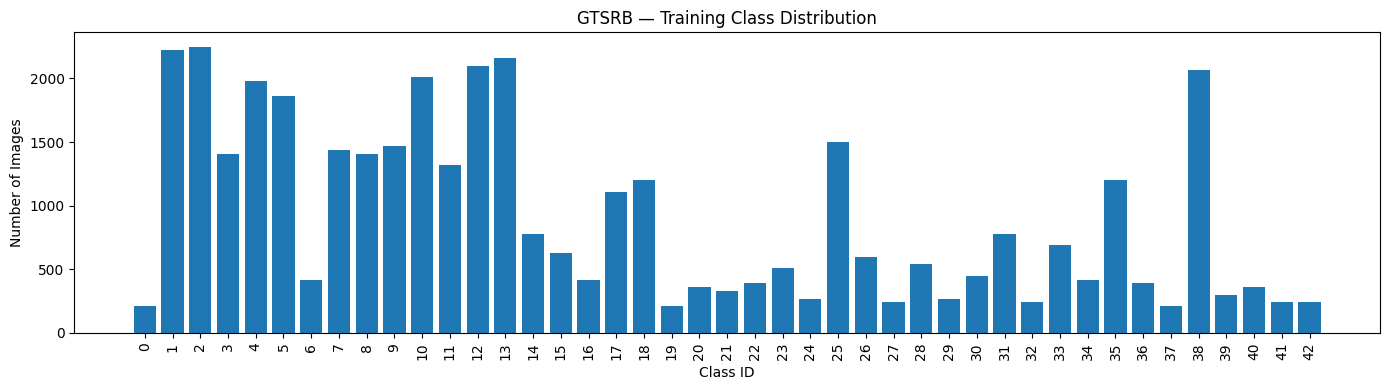

Original image size statistics:


,Width,Height
count,39209.000000,39209.000000
mean,50.835880,50.328930
std,24.306933,23.115423
min,25.000000,25.000000
25%,35.000000,35.000000
50%,43.000000,43.000000
75%,58.000000,58.000000
max,243.000000,225.000000


In [4]:

counts = train_df["ClassId"].value_counts().sort_index()

print("Training samples per class:")
display(counts.rename("count").to_frame())

plt.figure(figsize=(14, 4))
plt.bar(counts.index, counts.values)
plt.title("GTSRB — Training Class Distribution")
plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.xticks(range(NUM_CLASSES), rotation=90)
plt.tight_layout()
plt.show()

if {"Width", "Height"}.issubset(train_df.columns):
    print("Original image size statistics:")
    display(train_df[["Width", "Height"]].describe())


EDA: Display Sample Images

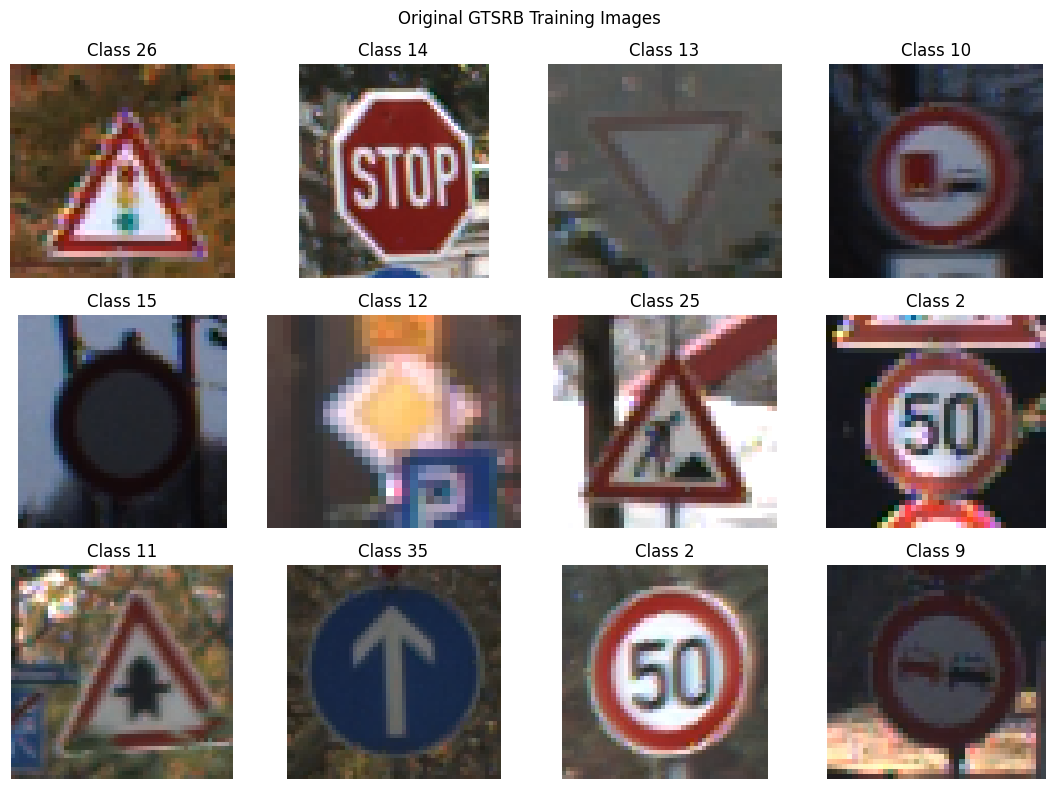

In [5]:

sample_df = train_df.sample(n=12, random_state=SEED)

fig, axes = plt.subplots(3, 4, figsize=(11, 8))

for ax, rec in zip(
    axes.flat, sample_df.itertuples(index=False)
):
    with Image.open(rec.image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(f"Class {rec.ClassId}")
    ax.axis("off")

plt.suptitle("Original GTSRB Training Images")
plt.tight_layout()
plt.show()


Track-Based Train / Validation Split

In [6]:
def extract_track_id(rec):
    # GTSRB training filename: class_track_frame.png
    stem = Path(
        str(rec.Path).replace("\\", "/")
    ).stem

    parts = stem.split("_")

    if len(parts) != 3 or not all(p.isdigit() for p in parts):
        raise ValueError(
            f"Unexpected training filename: {rec.Path}"
        )

    if int(parts[0]) != int(rec.ClassId):
        raise ValueError(
            f"Filename/CSV class mismatch: {rec.Path}"
        )

    return f"{int(rec.ClassId):02d}_{parts[1]}"

train_df["track_id"] = train_df.apply(
    extract_track_id, axis=1
)

tracks = train_df[
    ["track_id", "ClassId"]
].drop_duplicates()

if not tracks["track_id"].is_unique:
    raise ValueError("Conflicting track labels")

train_tracks, val_tracks = train_test_split(
    tracks["track_id"],
    test_size=0.20,
    stratify=tracks["ClassId"],
    random_state=SEED
)

train_split = train_df[
    train_df["track_id"].isin(train_tracks)
].copy()

val_split = train_df[
    train_df["track_id"].isin(val_tracks)
].copy()

assert set(train_split.track_id).isdisjoint(
    set(val_split.track_id)
)

assert len(train_split) + len(val_split) == len(train_df)

assert set(train_split.ClassId) == set(range(NUM_CLASSES))
assert set(val_split.ClassId) == set(range(NUM_CLASSES))

print("Train:", len(train_split))
print("Validation:", len(val_split))
print("Official Test:", len(test_df))
print("Track leakage between Train and Validation: NONE")


Train: 31350
Validation: 7859
Official Test: 12630
Track leakage between Train and Validation: NONE


Image Preprocessing & Export for CNN and YOLO-cls

In [7]:
if READY_ROOT.exists() and any(READY_ROOT.iterdir()):
    raise FileExistsError(
        f"{READY_ROOT} already contains files. "
        "Choose a fresh directory to avoid mixing outputs."
    )

for split_name in ("train", "val", "test"):
    for label in range(NUM_CLASSES):
        (READY_ROOT / split_name / f"{label:02d}").mkdir(
            parents=True, exist_ok=True
        )

manifest_rows = []

def export_split(df, split_name):
    for rec in tqdm(
        df.itertuples(index=False),
        total=len(df),
        desc=f"Export {split_name}"
    ):
        class_folder = f"{int(rec.ClassId):02d}"

        image_name = Path(
            str(rec.Path).replace("\\", "/")
        ).stem + ".png"

        destination = (
            READY_ROOT / split_name / class_folder / image_name
        )

        if destination.exists():
            raise RuntimeError(
                f"Output filename collision: {destination}"
            )

        with Image.open(rec.image_path) as img:
            img = ImageOps.pad(
                img.convert("RGB"),
                IMAGE_SIZE,
                method=Image.Resampling.LANCZOS,
                color=(0, 0, 0)
            )

            img.save(
                destination,
                format="PNG",
                compress_level=1
            )

        manifest_rows.append({
            "split": split_name,
            "source_path": rec.Path,
            "ClassId": int(rec.ClassId),
            "track_id": getattr(rec, "track_id", ""),
            "output_path": str(
                destination.relative_to(READY_ROOT)
            )
        })

export_split(train_split, "train")
export_split(val_split, "val")
export_split(test_df, "test")

manifest = pd.DataFrame(manifest_rows)

manifest.to_csv(
    READY_ROOT / "split_manifest.csv",
    index=False
)

print("Preprocessed dataset saved to:", READY_ROOT)


Export train:   0%|          | 0/31350 [00:00<?, ?it/s]

Export val:   0%|          | 0/7859 [00:00<?, ?it/s]

Export test:   0%|          | 0/12630 [00:00<?, ?it/s]

Preprocessed dataset saved to: /content/gtsrb_ready


Validate Preprocessed Dataset

In [8]:
split_frames = {
    "train": train_split,
    "val": val_split,
    "test": test_df
}

expected_folders = [
    f"{i:02d}" for i in range(NUM_CLASSES)
]

for split_name, df in split_frames.items():
    folder = READY_ROOT / split_name

    actual_folders = sorted(
        p.name for p in folder.iterdir() if p.is_dir()
    )

    assert actual_folders == expected_folders

    for label in range(NUM_CLASSES):
        expected = int((df["ClassId"] == label).sum())

        actual = sum(
            1 for _ in (
                folder / f"{label:02d}"
            ).glob("*.png")
        )

        assert actual == expected, (
            split_name, label, expected, actual
        )

    print(f"{split_name}: {len(df):,} images verified")

assert len(manifest) == len(train_df) + len(test_df)
assert manifest["output_path"].is_unique

sample_paths = [
    READY_ROOT / rel
    for rel in manifest["output_path"].sample(
        n=min(100, len(manifest)),
        random_state=SEED
    )
]

for path in sample_paths:
    with Image.open(path) as img:
        assert img.mode == "RGB"
        assert img.size == IMAGE_SIZE

config = {
    "dataset": "GTSRB",
    "task": "classification",
    "num_classes": NUM_CLASSES,
    "image_size": list(IMAGE_SIZE),
    "random_seed": SEED,
    "validation_split": "20% of training tracks",
    "test_split": "Original Test.csv",
    "preprocessing": "RGB + aspect-ratio-preserving padding",
    "augmentation": "Training stage only",
    "counts": {
        name: len(df)
        for name, df in split_frames.items()
    }
}

(READY_ROOT / "preprocessing_config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8"
)

print("All preprocessing validation checks passed.")
print("CNN dataset:", READY_ROOT)
print("YOLO-cls dataset:", READY_ROOT)


train: 31,350 images verified
val: 7,859 images verified
test: 12,630 images verified
All preprocessing validation checks passed.
CNN dataset: /content/gtsrb_ready
YOLO-cls dataset: /content/gtsrb_ready


Visual Check: Before vs. After Preprocessing

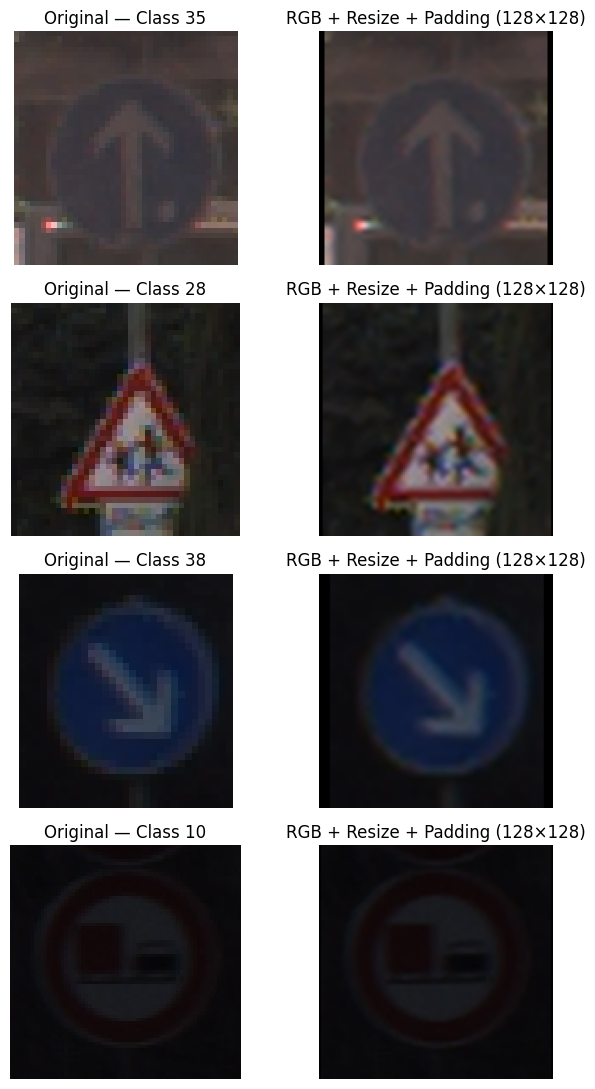

In [9]:
examples = train_split.sample(n=4, random_state=SEED)

fig, axes = plt.subplots(4, 2, figsize=(7, 11))

for i, rec in enumerate(examples.itertuples(index=False)):
    processed = (
        READY_ROOT
        / "train"
        / f"{int(rec.ClassId):02d}"
        / (Path(rec.Path).stem + ".png")
    )

    with Image.open(rec.image_path) as original:
        axes[i, 0].imshow(original.convert("RGB"))

    with Image.open(processed) as standardized:
        axes[i, 1].imshow(standardized)

    axes[i, 0].set_title(
        f"Original — Class {rec.ClassId}"
    )
    axes[i, 1].set_title(
        "RGB + Resize + Padding (128×128)"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


## 2. Model Development and Training
**CNN & YOLO-cls**

###CNN Classification

Install Libraries & Import CNN Dependencies

In [10]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time
import gc
from pathlib import Path
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

SEED = 42
IMG = 128
IMAGE_SIZE = (IMG, IMG)
BATCH_SIZE = 64
NUM_CLASSES = 43
EPOCHS = 20

tf.keras.utils.set_random_seed(SEED)

# Use mixed precision only when a GPU is available.
if tf.config.list_physical_devices("GPU"):
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
else:
    tf.keras.mixed_precision.set_global_policy("float32")

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))
print("Model: ResNet18 (from scratch; no pretrained weights)")


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Model: ResNet18 (from scratch; no pretrained weights)


Load Preprocessed Dataset

In [11]:
READY_ROOT = Path("/content/gtsrb_ready")
TRAIN_DIR = READY_ROOT / "train"
VAL_DIR = READY_ROOT / "val"
TEST_DIR = READY_ROOT / "test"

# Keep exactly the same train/validation/test folders and split used by YOLO.
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False
)

class_names = train_ds.class_names
assert len(class_names) == NUM_CLASSES
assert class_names == val_ds.class_names == test_ds.class_names

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Train/validation/test folders match the YOLO split.")
print("Number of classes:", len(class_names))

Found 31350 files belonging to 43 classes.
Found 7859 files belonging to 43 classes.
Found 12630 files belonging to 43 classes.
Train/validation/test folders match the YOLO split.
Number of classes: 43


ResNet18 Model Architecture

In [12]:
def residual_block(x, filters, stride=1, name="res"):
    shortcut = x

    x = layers.Conv2D(
        filters, 3, strides=stride, padding="same",
        use_bias=False, kernel_initializer="he_normal",
        name=f"{name}_conv1"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    x = layers.Conv2D(
        filters, 3, strides=1, padding="same",
        use_bias=False, kernel_initializer="he_normal",
        name=f"{name}_conv2"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)

    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, 1, strides=stride, padding="same",
            use_bias=False, kernel_initializer="he_normal",
            name=f"{name}_shortcut_conv"
        )(shortcut)
        shortcut = layers.BatchNormalization(
            name=f"{name}_shortcut_bn"
        )(shortcut)

    x = layers.Add(name=f"{name}_add")([x, shortcut])
    return layers.Activation("relu", name=f"{name}_out")(x)


def build_resnet18(num_classes=NUM_CLASSES, image_size=None, dropout_rate=0.30):
    model_image_size = int(image_size or IMG)
    inputs = layers.Input(shape=(model_image_size, model_image_size, 3), name="image")

    # Light augmentation; source images are already letterboxed to 128x128.
    x = layers.RandomRotation(0.04)(inputs)
    x = layers.RandomTranslation(0.04, 0.04)(x)
    x = layers.RandomContrast(0.10)(x)
    x = layers.Rescaling(1.0 / 255.0)(x)

    x = layers.Conv2D(
        64, 7, strides=2, padding="same",
        use_bias=False, kernel_initializer="he_normal"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(pool_size=3, strides=2, padding="same")(x)

    # ResNet18: two residual blocks at each of four feature stages.
    x = residual_block(x, 64, stride=1, name="stage1_block1")
    x = residual_block(x, 64, stride=1, name="stage1_block2")
    x = residual_block(x, 128, stride=2, name="stage2_block1")
    x = residual_block(x, 128, stride=1, name="stage2_block2")
    x = residual_block(x, 256, stride=2, name="stage3_block1")
    x = residual_block(x, 256, stride=1, name="stage3_block2")
    x = residual_block(x, 512, stride=2, name="stage4_block1")
    x = residual_block(x, 512, stride=1, name="stage4_block2")

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(float(dropout_rate))(x)
    outputs = layers.Dense(
        num_classes, activation="softmax", dtype="float32", name="predictions"
    )(x)

    return Model(inputs, outputs, name="ResNet18_GTSRB")


cnn_model = build_resnet18()
cnn_model.summary()

Model: "ResNet18_GTSRB"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 128, 128,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation     │ (None, 128, 128,  │          0 │ image[0][0]       │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_translation  │ (None, 128, 128,  │          0 │ random_rotation[… │
│ (RandomTranslation) │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_contrast     │ (None, 128, 128,  │          0 │ random_translati… │
│ (RandomContrast)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 128, 128,  │          0 │ random_contrast[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │      9,408 │ rescaling[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_conv1 │ (None, 32, 32,    │     36,864 │ max_pooling2d[0]… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_bn1   │ (None, 32, 32,    │        256 │ stage1_block1_co… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_relu1 │ (None, 32, 32,    │          0 │ stage1_block1_bn… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_conv2 │ (None, 32, 32,    │     36,864 │ stage1_block1_re… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_bn2   │ (None, 32, 32,    │        256 │ stage1_block1_co… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_add   │ (None, 32, 32,    │          0 │ stage1_block1_bn… │
│ (Add)               │ 64)               │            │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_out   │ (None, 32, 32,    │          0 │ stage1_block1_ad… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block2_conv1 │ (None, 32, 32,    │     36,864 │ stage1_block1_ou

 Total params: 11,208,171 (42.76 MB)

 Trainable params: 11,198,571 (42.72 MB)

 Non-trainable params: 9,600 (37.50 KB)

ResNet18 Model Compilation

In [13]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("ResNet18 compiled successfully.")

ResNet18 compiled successfully.


ResNet18 Baseline Training (Before Hyperparameter Tuning)

In [14]:
callbacks = [
    EarlyStopping(
        monitor="val_loss", patience=3,
        restore_best_weights=True, verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss", factor=0.5,
        patience=2, min_lr=1e-6, verbose=1
    ),
    ModelCheckpoint(
        "/content/best_cnn_baseline.keras",
        monitor="val_accuracy", save_best_only=True, verbose=1
    )
]

# Synchronize GPU before/after timing for an accurate measurement.
if tf.config.list_physical_devices("GPU"):
    try:
        tf.experimental.async_wait()
    except Exception:
        pass

start_time = time.time()
cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)
if tf.config.list_physical_devices("GPU"):
    try:
        tf.experimental.async_wait()
    except Exception:
        pass

cnn_training_time = time.time() - start_time
tuned_cnn_training_time = cnn_training_time

print(f"ResNet18 training time: {cnn_training_time:.2f} seconds")
print(f"Best validation accuracy: {max(cnn_history.history['val_accuracy'])*100:.2f}%")

# Keep the legacy checkpoint filename for compatibility with later notebook cells.
best_resnet18 = tf.keras.models.load_model("/content/best_cnn_baseline.keras")
best_resnet18.save("/content/best_cnn_baseline.keras")

Epoch 1/20
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.3798 - loss: 2.4056
Epoch 1: val_accuracy improved from None to 0.89566, saving model to /content/best_cnn_baseline.keras

Epoch 1: finished saving model to /content/best_cnn_baseline.keras
490/490 ━━━━━━━━━━━━━━━━━━━━ 73s 106ms/step - accuracy: 0.6470 - loss: 1.2649 - val_accuracy: 0.8957 - val_loss: 0.3558 - learning_rate: 0.0010
Epoch 2/20
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.9591 - loss: 0.1353
Epoch 2: val_accuracy improved from 0.89566 to 0.95101, saving model to /content/best_cnn_baseline.keras

Epoch 2: finished saving model to /content/best_cnn_baseline.keras
490/490 ━━━━━━━━━━━━━━━━━━━━ 49s 99ms/step - accuracy: 0.9663 - loss: 0.1104 - val_accuracy: 0.9510 - val_loss: 0.1917 - learning_rate: 0.0010
Epoch 3/20
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.9842 - loss: 0.0500
Epoch 3: val_accuracy improved from 0.95101 to 0.96615, saving model to /content/best_cnn_baseline.keras

Epo

ResNet18 Baseline Training Performance Visualization

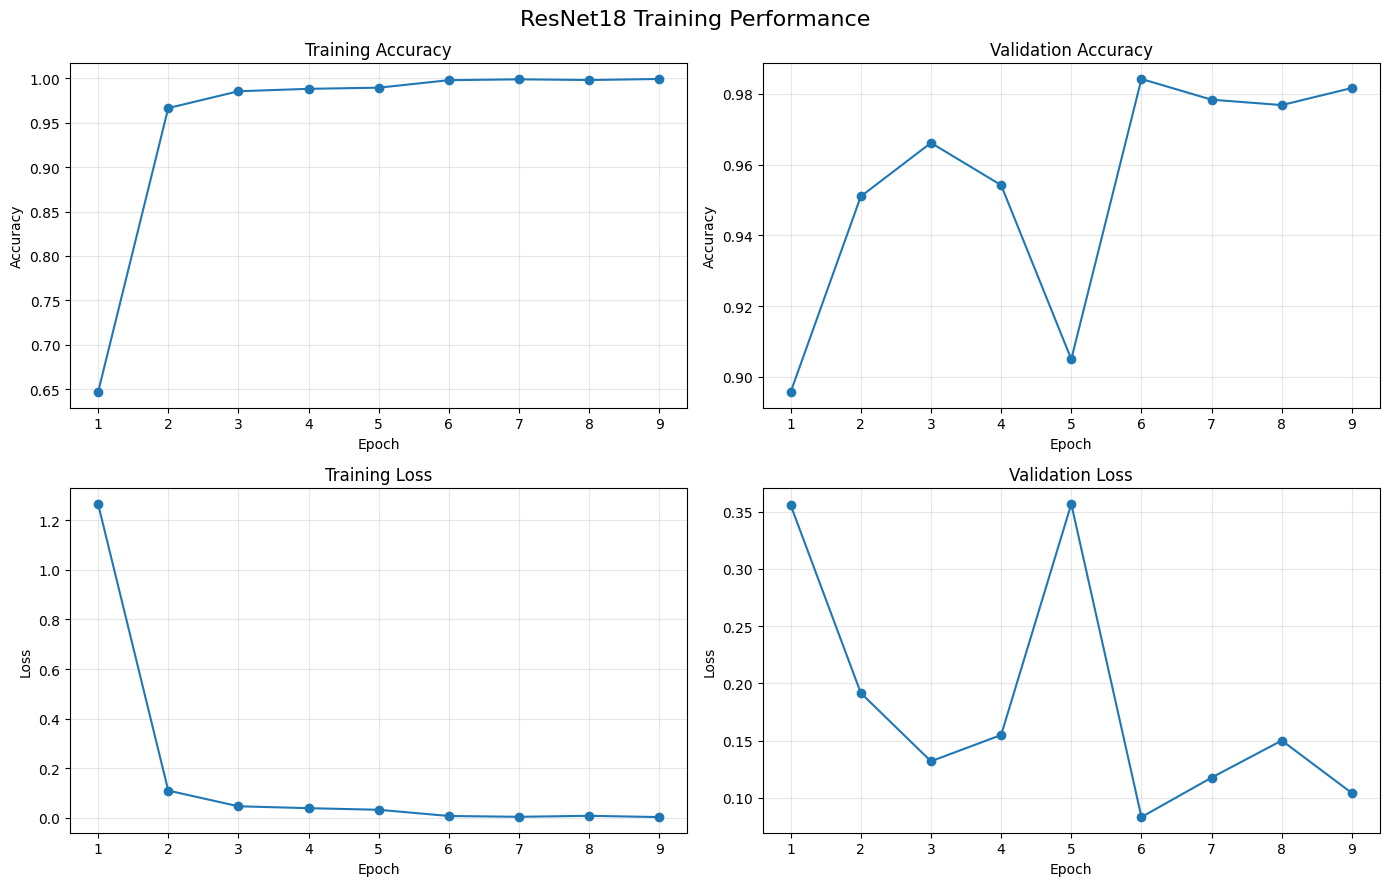

In [15]:
# Visualize the metrics recorded during the existing ResNet18 training run.
# This cell uses cnn_history and does not train the model again.

epochs = range(1, len(cnn_history.history["accuracy"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Training Accuracy
axes[0, 0].plot(epochs, cnn_history.history["accuracy"], marker="o")
axes[0, 0].set_title("Training Accuracy")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Accuracy")
axes[0, 0].grid(True, alpha=0.3)

# Validation Accuracy
axes[0, 1].plot(epochs, cnn_history.history["val_accuracy"], marker="o")
axes[0, 1].set_title("Validation Accuracy")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].grid(True, alpha=0.3)

# Training Loss
axes[1, 0].plot(epochs, cnn_history.history["loss"], marker="o")
axes[1, 0].set_title("Training Loss")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Loss")
axes[1, 0].grid(True, alpha=0.3)

# Validation Loss
axes[1, 1].plot(epochs, cnn_history.history["val_loss"], marker="o")
axes[1, 1].set_title("Validation Loss")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Loss")
axes[1, 1].grid(True, alpha=0.3)

fig.suptitle("ResNet18 Training Performance", fontsize=16)
plt.tight_layout()
plt.show()

CNN Baseline Evaluation and Saving

In [16]:
best_cnn = tf.keras.models.load_model("/content/best_cnn_baseline.keras")
test_loss, test_accuracy = best_cnn.evaluate(test_ds, verbose=1)

print("ResNet18 Test Loss:", test_loss)
print("ResNet18 Test Accuracy:", test_accuracy)
print("ResNet18 Training Time:", cnn_training_time)

198/198 ━━━━━━━━━━━━━━━━━━━━ 11s 49ms/step - accuracy: 0.9816 - loss: 0.0857
ResNet18 Test Loss: 0.0856531634926796
ResNet18 Test Accuracy: 0.9816310405731201
ResNet18 Training Time: 660.4704201221466


ResNet18 Baseline Configuration (Before Hyperparameter Search)

In [17]:
from pathlib import Path

READY_ROOT = Path("/content/gtsrb_ready")

print("Dataset exists:", READY_ROOT.exists())
print("Train exists:", (READY_ROOT / "train").exists())
print("Validation exists:", (READY_ROOT / "val").exists())
print("Test exists:", (READY_ROOT / "test").exists())

Dataset exists: True
Train exists: True
Validation exists: True
Test exists: True


CNN Hyperparameter Search (Matched Search Budget with YOLO-cls)

In [18]:
# ============================================================
# CNN HYPERPARAMETER SEARCH — matched protocol with YOLO-cls
# Same development subset fraction (25%), search epochs (4),
# batch size (64), and coordinate-search trial budget (8 trials).
# Search resolution is 64x64 to match YOLO search imgsz=64.
# Final CNN retraining uses the full 128x128 development data.
# ============================================================
import gc, time, random, shutil, os
from pathlib import Path
import numpy as np, pandas as pd, tensorflow as tf

SEED = 42
CNN_SEARCH_FRAC = 0.25
CNN_SEARCH_EPOCHS = 4
CNN_SEARCH_SIZE = 64
CNN_SEARCH_BATCH = 64
CNN_SEARCH_ROOT = Path('/content/gtsrb_cnn_search')
CNN_SEARCH_RUNS = Path('/content/cnn_search_runs')

# Rebuild the deterministic subset to avoid stale symlinks from older runs.
if CNN_SEARCH_ROOT.exists():
    shutil.rmtree(CNN_SEARCH_ROOT)
for split in ('train', 'val'):
    rng = random.Random(SEED + (0 if split == 'train' else 1))
    for class_dir in sorted((READY_ROOT / split).iterdir()):
        if not class_dir.is_dir():
            continue
        files = sorted(class_dir.glob('*.png'))
        if not files:
            continue
        keep_n = max(1, int(round(len(files) * CNN_SEARCH_FRAC)))
        selected = sorted(rng.sample(files, min(keep_n, len(files))))
        target = CNN_SEARCH_ROOT / split / class_dir.name
        target.mkdir(parents=True, exist_ok=True)
        for f in selected:
            os.symlink(f, target / f.name)

print('CNN search subset:', {s: sum(1 for _ in (CNN_SEARCH_ROOT/s).rglob('*.png')) for s in ('train','val')})

# Match the YOLO coordinate-search parameter candidates.
CNN_BASELINE = {'learning_rate': 1e-3, 'optimizer': 'Adam', 'weight_decay': 5e-4, 'dropout': 0.0}
CNN_SPACE = {
    'learning_rate': [1e-2, 3e-3, 1e-3, 3e-4],
    'optimizer': ['Adam', 'AdamW'],
    'weight_decay': [0.0, 5e-4, 5e-3],
    'dropout': [0.0, 0.2],
}

cnn_search_train = tf.keras.utils.image_dataset_from_directory(
    CNN_SEARCH_ROOT/'train', image_size=(CNN_SEARCH_SIZE, CNN_SEARCH_SIZE),
    batch_size=CNN_SEARCH_BATCH, label_mode='int', shuffle=True, seed=SEED)
cnn_search_val = tf.keras.utils.image_dataset_from_directory(
    CNN_SEARCH_ROOT/'val', image_size=(CNN_SEARCH_SIZE, CNN_SEARCH_SIZE),
    batch_size=CNN_SEARCH_BATCH, label_mode='int', shuffle=False)
assert cnn_search_train.class_names == cnn_search_val.class_names
cnn_search_train = cnn_search_train.prefetch(tf.data.AUTOTUNE)
cnn_search_val = cnn_search_val.prefetch(tf.data.AUTOTUNE)

cnn_trial_counter = 0
def run_cnn_trial(cfg):
    global cnn_trial_counter
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_resnet18(NUM_CLASSES, image_size=CNN_SEARCH_SIZE, dropout_rate=cfg['dropout'])
    if cfg['optimizer'] == 'AdamW':
        opt = tf.keras.optimizers.AdamW(learning_rate=float(cfg['learning_rate']), weight_decay=float(cfg['weight_decay']))
    else:
        opt = tf.keras.optimizers.Adam(learning_rate=float(cfg['learning_rate']))
    model.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    callbacks_search = [
        tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=CNN_SEARCH_EPOCHS, restore_best_weights=True),
    ]
    t0 = time.time()
    hist = model.fit(cnn_search_train, validation_data=cnn_search_val,
                     epochs=CNN_SEARCH_EPOCHS, callbacks=callbacks_search, verbose=0)
    elapsed = time.time() - t0
    score = float(max(hist.history['val_accuracy']))
    cnn_trial_counter += 1
    print(f"CNN trial {cnn_trial_counter}/8 | {cfg} -> val_accuracy={score:.4f} | {elapsed:.1f}s", flush=True)
    del model
    gc.collect()
    return score

def cnn_coordinate_search(space, baseline, run_fn):
    best = baseline.copy(); cache = {}; log = []
    def evaluate(cfg):
        key = tuple(sorted(cfg.items()))
        if key not in cache:
            score = run_fn(cfg.copy()); cache[key] = score
            log.append({**cfg, 'val_accuracy': score})
        return cache[key]
    best_score = evaluate(best)
    for parameter, values in space.items():
        candidates = [(v, evaluate({**best, parameter: v})) for v in values]
        chosen, score = max(candidates, key=lambda item: item[1])
        best[parameter] = chosen; best_score = score
        print(f'Best {parameter}: {chosen} | val_accuracy={score:.4f}')
    return best, best_score, pd.DataFrame(log)

cnn_search_start = time.time()
best_cnn_params, best_cnn_val_accuracy, cnn_search_results = cnn_coordinate_search(
    CNN_SPACE, CNN_BASELINE, run_cnn_trial)
cnn_search_time = time.time() - cnn_search_start
cnn_search_results.to_csv('/content/cnn_search_results.csv', index=False)
print('Selected CNN parameters:', best_cnn_params)
print(f'Best search validation accuracy: {best_cnn_val_accuracy:.4f}')
print(f'CNN search trials: {len(cnn_search_results)} | search time: {cnn_search_time/60:.2f} min')
assert len(cnn_search_results) == 8, f'Expected 8 unique CNN trials, got {len(cnn_search_results)}'


CNN search subset: {'train': 7836, 'val': 1964}
Found 7836 files belonging to 43 classes.
Found 1964 files belonging to 43 classes.
CNN trial 1/8 | {'learning_rate': 0.001, 'optimizer': 'Adam', 'weight_decay': 0.0005, 'dropout': 0.0} -> val_accuracy=0.9089 | 59.6s
CNN trial 2/8 | {'learning_rate': 0.01, 'optimizer': 'Adam', 'weight_decay': 0.0005, 'dropout': 0.0} -> val_accuracy=0.7617 | 60.5s
CNN trial 3/8 | {'learning_rate': 0.003, 'optimizer': 'Adam', 'weight_decay': 0.0005, 'dropout': 0.0} -> val_accuracy=0.9364 | 50.5s
CNN trial 4/8 | {'learning_rate': 0.0003, 'optimizer': 'Adam', 'weight_decay': 0.0005, 'dropout': 0.0} -> val_accuracy=0.8223 | 50.8s
Best learning_rate: 0.003 | val_accuracy=0.9364
CNN trial 5/8 | {'learning_rate': 0.003, 'optimizer': 'AdamW', 'weight_decay': 0.0005, 'dropout': 0.0} -> val_accuracy=0.8641 | 62.9s
Best optimizer: Adam | val_accuracy=0.9364
CNN trial 6/8 | {'learning_rate': 0.003, 'optimizer': 'Adam', 'weight_decay': 0.0, 'dropout': 0.0} -> val_accur

CNN Final Training Configuration (Selected Hyperparameters)

In [19]:
# Final CNN builder: ResNet18 with selected hyperparameters from CNN_SPACE.
def build_cnn(lr, dropout, optimizer_name, weight_decay):
    model = build_resnet18(NUM_CLASSES, image_size=IMG, dropout_rate=dropout)
    if optimizer_name == "AdamW":
        optimizer = tf.keras.optimizers.AdamW(learning_rate=float(lr), weight_decay=float(weight_decay))
    else:
        optimizer = tf.keras.optimizers.Adam(learning_rate=float(lr))
    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

print("Final CNN model builder ready; selected parameters:", best_cnn_params)

Final CNN model builder ready; selected parameters: {'learning_rate': 0.003, 'optimizer': 'Adam', 'weight_decay': 0.0005, 'dropout': 0.0}


CNN Baseline Validation Accuracy Across Epochs

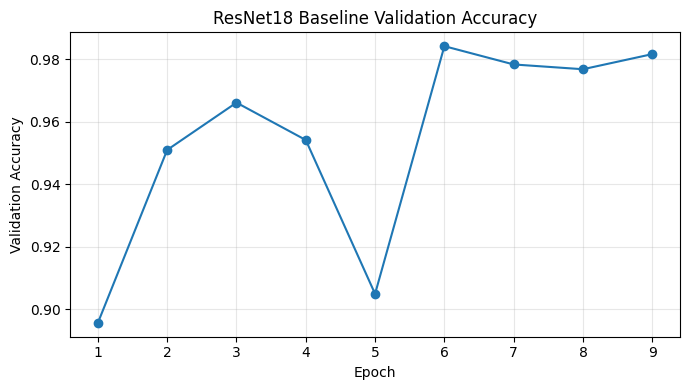

In [20]:
# Show validation accuracy from the same training history (no additional training).
plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(cnn_history.history["val_accuracy"]) + 1),
    cnn_history.history["val_accuracy"],
    marker="o"
)
plt.title("ResNet18 Baseline Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Selected ResNet18 Hyperparameters (from actual coordinate search)

In [21]:
optimal_cnn_df = pd.DataFrame([best_cnn_params])
optimal_cnn_df["Best Search Validation Accuracy (%)"] = best_cnn_val_accuracy * 100
optimal_cnn_df["Search Trials"] = len(cnn_search_results)
optimal_cnn_df["Search Time (seconds)"] = cnn_search_time
print("Selected ResNet18 Configuration:")
display(optimal_cnn_df)


Selected ResNet18 Configuration:


,learning_rate,optimizer,weight_decay,dropout,Best Search Validation Accuracy (%),Search Trials,Search Time (seconds)
0,0.003,Adam,0.0005,0.0,93.63544,8,461.265016


Generating CNN Hyperparameter Search Visualizations...


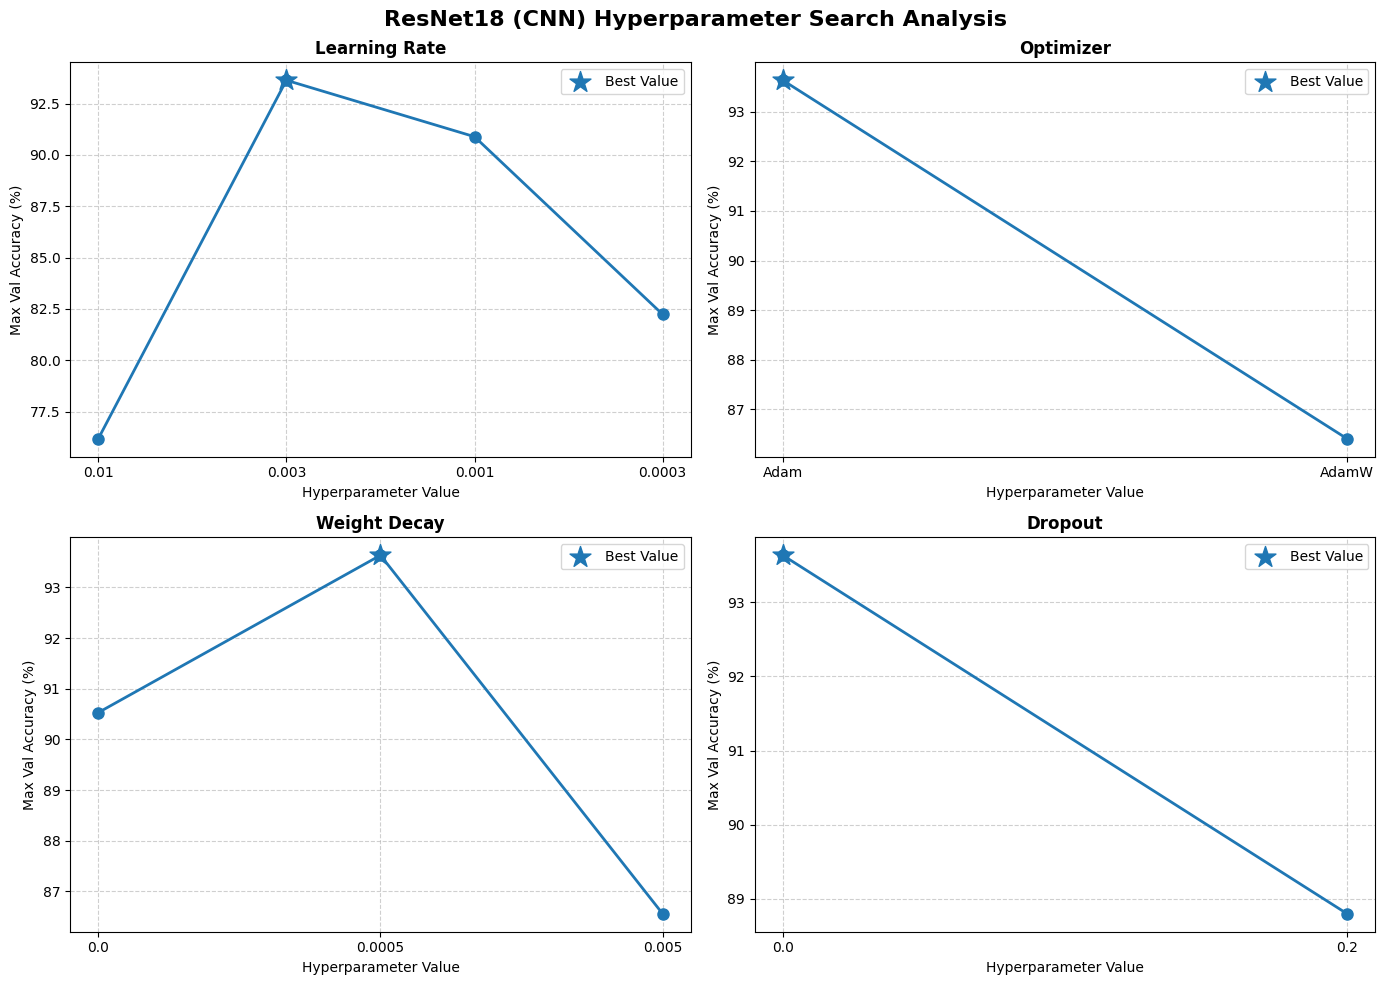

In [23]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

# 1. Load CNN search results
cnn_results_path = Path('/content/cnn_search_results.csv')

# 2. Define CNN hyperparameter space and search orders
cnn_space = {
    'learning_rate': [1e-2, 3e-3, 1e-3, 3e-4],
    'optimizer': ['Adam', 'AdamW'],
    'weight_decay': [0.0, 5e-4, 5e-3],
    'dropout': [0.0, 0.2]
}

def plot_cnn_hyperparameters(df_path, space):
    if not df_path.exists():
        print(f"Data for CNN search results not found at {df_path}. Run the CNN coordinate search first.")
        return

    df = pd.read_csv(df_path)
    params = list(space.keys())

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()

    for idx, param in enumerate(params):
        ax = axes[idx]
        # Find the max validation accuracy for each unique value of the current hyperparameter
        grouped = df.groupby(param)['val_accuracy'].max().reset_index()

        # Sort the values based on the defined search space order
        grouped['sort_order'] = grouped[param].map(lambda v: space[param].index(v) if v in space[param] else 999)
        grouped = grouped.sort_values('sort_order')

        x_labels = grouped[param].astype(str).tolist()
        y_values = (grouped['val_accuracy'] * 100).tolist()

        ax.plot(x_labels, y_values, marker='o', color='tab:blue', linewidth=2, markersize=8)

        # Highlight the best value with a blue star to match YOLO plots
        best_idx = np.argmax(y_values)
        ax.scatter([x_labels[best_idx]], [y_values[best_idx]], color='tab:blue', marker='*', s=250, zorder=5, label='Best Value')

        ax.set_title(f"{param.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
        ax.set_xlabel("Hyperparameter Value")
        ax.set_ylabel("Max Val Accuracy (%)")
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend()

    plt.suptitle("ResNet18 (CNN) Hyperparameter Search Analysis", fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()

# Generate plots specifically for CNN
print("Generating CNN Hyperparameter Search Visualizations...")
plot_cnn_hyperparameters(cnn_results_path, cnn_space)

Retrain CNN with Selected Hyperparameters on Full Development Data

In [ ]:
# Train a fresh final ResNet18 using the selected search configuration.
# This replaces the baseline checkpoint for all final comparisons.
import gc, time

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
tuned_cnn_model = build_cnn(
    lr=best_cnn_params["learning_rate"],
    dropout=best_cnn_params["dropout"],
    optimizer_name=best_cnn_params["optimizer"],
    weight_decay=best_cnn_params["weight_decay"]
)
CNN_TUNED_EPOCHS = 20
cnn_tuned_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy", mode="max", patience=4,
        restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2,
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_cnn_tuned.keras", monitor="val_accuracy",
        mode="max", save_best_only=True, verbose=1
    )
]
if tf.config.list_physical_devices("GPU"):
    try: tf.experimental.async_wait()
    except Exception: pass
cnn_tuned_start = time.time()
cnn_tuned_history = tuned_cnn_model.fit(
    train_ds, validation_data=val_ds, epochs=CNN_TUNED_EPOCHS,
    callbacks=cnn_tuned_callbacks, verbose=1
)
if tf.config.list_physical_devices("GPU"):
    try: tf.experimental.async_wait()
    except Exception: pass
tuned_cnn_training_time = time.time() - cnn_tuned_start
cnn_training_time = tuned_cnn_training_time
best_cnn_val_accuracy = float(max(cnn_tuned_history.history["val_accuracy"]))
best_tuned_cnn = tf.keras.models.load_model("/content/best_cnn_tuned.keras", compile=False)
best_tuned_cnn.save("/content/best_cnn.keras")
print("Final tuned CNN checkpoint: /content/best_cnn_tuned.keras")
print("Selected parameters:", best_cnn_params)
print(f"Best final validation accuracy: {best_cnn_val_accuracy*100:.2f}%")
print(f"Final CNN training time: {tuned_cnn_training_time:.1f} seconds")


Epoch 1/20
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.4340 - loss: 2.1060
Epoch 1: val_accuracy improved from None to 0.81817, saving model to /content/best_cnn_tuned.keras

Epoch 1: finished saving model to /content/best_cnn_tuned.keras
490/490 ━━━━━━━━━━━━━━━━━━━━ 81s 139ms/step - accuracy: 0.6912 - loss: 1.0647 - val_accuracy: 0.8182 - val_loss: 0.7971 - learning_rate: 0.0010
Epoch 2/20
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.9622 - loss: 0.1205
Epoch 2: val_accuracy improved from 0.81817 to 0.92544, saving model to /content/best_cnn_tuned.keras

Epoch 2: finished saving model to /content/best_cnn_tuned.keras
490/490 ━━━━━━━━━━━━━━━━━━━━ 65s 133ms/step - accuracy: 0.9723 - loss: 0.0890 - val_accuracy: 0.9254 - val_loss: 0.2555 - learning_rate: 0.0010
Epoch 3/20
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.9821 - loss: 0.0603
Epoch 3: val_accuracy improved from 0.92544 to 0.94427, saving model to /content/best_cnn_tuned.keras

Epoch 3: finis

ResNet18 Model Evaluation

In [ ]:
best_tuned_cnn = tf.keras.models.load_model("/content/best_cnn_tuned.keras")
test_ds = tf.keras.utils.image_dataset_from_directory(
    READY_ROOT / "test", image_size=(IMG, IMG), batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False
).prefetch(tf.data.AUTOTUNE)
tuned_test_loss, tuned_test_accuracy = best_tuned_cnn.evaluate(test_ds, verbose=1)
print("\nResNet18 Tuned Official Test Results")
print(f"Test Loss: {tuned_test_loss:.4f}")
print(f"Test Accuracy: {tuned_test_accuracy*100:.2f}%")
print(f"Final Training Time: {tuned_cnn_training_time:.2f} seconds")


Found 12630 files belonging to 43 classes.
198/198 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.9817 - loss: 0.0955

ResNet18 Tuned Official Test Results
Test Loss: 0.0955
Test Accuracy: 98.17%
Final Training Time: 1446.36 seconds


Tuned CNN Results

In [ ]:
cnn_comparison = pd.DataFrame({
    "Metric": ["Test Accuracy (%)", "Test Loss", "Final Training Time (seconds)", "Hyperparameter Search Time (seconds)"],
    "ResNet18 (Tuned)": [tuned_test_accuracy*100, tuned_test_loss, tuned_cnn_training_time, cnn_search_time]
})
print("Final Tuned ResNet18 Results")
display(cnn_comparison.round(4))

Final Tuned ResNet18 Results


,Metric,ResNet18 (Tuned)
0,Test Accuracy (%),98.1710
1,Test Loss,0.0955
2,Final Training Time (seconds),1446.3623
3,Hyperparameter Search Time (seconds),462.4235


**Note on the CNN tuning result.** The CNN hyperparameters were selected by a short coordinate search (8 trials, 25% stratified subset, 4 epochs, 64x64 inputs) using *validation* accuracy only. The test set was not used for selection. A configuration that wins the short search is therefore not guaranteed to beat the baseline after full 128x128 retraining, so the baseline-vs-tuned test accuracies above should be reported as measured, without describing the tuned model as an improvement unless the numbers show one.

###YOLO Classification

Install YOLO-cls Libraries

In [ ]:

# Install Ultralytics YOLO
!pip install -q ultralytics

# Import libraries
import os
import time
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision.transforms as T

from pathlib import Path
from ultralytics import YOLO
from ultralytics.data.augment import ClassifyLetterBox
from ultralytics.data.dataset import ClassificationDataset
from ultralytics.models.yolo.classify import (
    ClassificationTrainer,
    ClassificationValidator
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Check environment
print("PyTorch version:", torch.__version__)
print("Ultralytics version:", __import__("ultralytics").__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. Training will use CPU.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch version: 2.14.1+cu130
Ultralytics version: 8.4.216
CUDA available: True
GPU: Tesla T4


Prepare YOLO-cls Dataset

In [ ]:

# Dataset path
YOLO_DATASET = Path("/content/gtsrb_ready")

TRAIN_DIR = YOLO_DATASET / "train"
VAL_DIR = YOLO_DATASET / "val"
TEST_DIR = YOLO_DATASET / "test"

# Dataset configuration
IMAGE_SIZE = 128
NUM_CLASSES = 43
BATCH_SIZE = 64
EPOCHS = 30

# Expected dataset sizes
EXPECTED_COUNTS = {
    "train": 31350,
    "val": 7859,
    "test": 12630
}

# Check dataset directories
assert YOLO_DATASET.exists(), "Dataset directory not found!"

for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    assert folder.exists(), f"Missing directory: {folder}"

# Check class folders
expected_classes = [f"{i:02d}" for i in range(NUM_CLASSES)]

for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    actual_classes = sorted(
        [p.name for p in folder.iterdir() if p.is_dir()]
    )
    assert actual_classes == expected_classes, (
        f"Incorrect class folders in {folder}"
    )

# Count images
valid_extensions = {".png", ".jpg", ".jpeg"}

for split, folder in [
    ("train", TRAIN_DIR),
    ("val", VAL_DIR),
    ("test", TEST_DIR)
]:
    image_paths = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in valid_extensions
    ]

    actual_count = len(image_paths)

    print(f"{split.capitalize()} images: {actual_count:,}")

    assert actual_count == EXPECTED_COUNTS[split], (
        f"Unexpected number of images in {split}"
    )

print("\nNumber of classes:", NUM_CLASSES)
print("Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Dataset verification completed successfully!")


Train images: 31,350
Val images: 7,859
Test images: 12,630

Number of classes: 43
Image size: 128 x 128
Dataset verification completed successfully!


YOLO-cls Model Configuration

In [ ]:
import math, gc, os, time
import torch.nn.functional as F


DATA_SIZE      = 128
YOLO_BASE_MIN  = 4.5
YOLO_TUNED_MIN = 4.5
AUG_MODE       = "gpu"
def gpu_augment(x, deg=18.0, trans=0.05, scale=(0.9, 1.1), contrast=0.1):
    """Same ranges as the original CPU pipeline (rotation +-18 deg, translation +-5%, scale 0.9-1.1,
    contrast +-10%), applied to a whole batch on the GPU. x: float tensor [B,3,H,W] in [0,1]."""
    x = x.float(); B = x.shape[0]; d = x.device
    ang = (torch.rand(B, device=d) * 2 - 1) * deg * math.pi / 180.0
    sc = torch.empty(B, device=d).uniform_(scale[0], scale[1])
    tx = (torch.rand(B, device=d) * 2 - 1) * trans * 2          # affine_grid coordinates span [-1, 1]
    ty = (torch.rand(B, device=d) * 2 - 1) * trans * 2
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)   # [B,2,3]
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    f = torch.empty(B, 1, 1, 1, device=d).uniform_(1 - contrast, 1 + contrast)
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    return ((x - m) * f + m).clamp_(0, 1)

# Custom GTSRB classification dataset
class GTSRBClassificationDataset(ClassificationDataset):
    def __init__(self, root, args, augment=False, prefix="", names=None):
        super().__init__(root, args, augment, prefix, names)
        s_ = int(args.imgsz)
        # images are already letterboxed to DATA_SIZE on disk; only resize when a smaller imgsz is requested
        pre = [T.Resize((s_, s_))] if s_ != DATA_SIZE else []
        if augment and AUG_MODE == "cpu":
            self.torch_transforms = T.Compose(pre + [
                T.RandomAffine(degrees=18, translate=(0.05, 0.05), scale=(0.9, 1.1)),
                T.ColorJitter(contrast=0.1), T.ToTensor()])
        else:                                   # GPU mode: the CPU only decodes; augmentation happens in preprocess_batch
            self.torch_transforms = T.Compose(pre + [T.ToTensor()])

# Custom trainer
class GTSRBClassificationTrainer(ClassificationTrainer):
    def build_dataset(self, img_path, mode="train", batch=None):
        return GTSRBClassificationDataset(
            root=img_path, args=self.args, augment=(mode == "train"),
            prefix="train" if mode == "train" else self.args.split, names=self.data["names"])

    def preprocess_batch(self, batch):
        batch = super().preprocess_batch(batch)
        if AUG_MODE == "gpu" and self.model.training:
            batch["img"] = gpu_augment(batch["img"])
        return batch

# Custom validator
class GTSRBClassificationValidator(ClassificationValidator):
    def build_dataset(self, img_path):
        return GTSRBClassificationDataset(
            root=img_path, args=self.args, augment=False, prefix=self.args.split, names=self.names)

def train_with_fallback(model_ctor, **kw):
    """Train; if the GPU-augmentation path raises, retry once with the original CPU augmentation."""
    global AUG_MODE
    model = model_ctor()
    try:
        model.train(**kw)
        return model
    except Exception as e:
        if AUG_MODE != "gpu":
            raise
        print("\nGPU-augmentation path failed:", repr(e)[:300], "\n-> falling back to CPU augmentation")
        AUG_MODE = "cpu"; gc.collect(); torch.cuda.empty_cache()
        model = model_ctor(); model.train(**kw)
        return model

# Build YOLO classification model from scratch (training below creates fresh models; this one is for the summary)
yolo_model = YOLO("yolo26n-cls.yaml")
yolo_model.info()

print("\nYOLO classification model configured successfully!")
print("Initialization: From scratch | classes:", NUM_CLASSES, "| image size:", IMAGE_SIZE)
print(f"Plan: baseline {YOLO_BASE_MIN} min + search (~6-8 min) + tuned {YOLO_TUNED_MIN} min + evaluation  =>  about 18-22 min")

YOLO26n-cls summary: 86 layers, 2,812,104 parameters, 2,812,104 gradients, 3.3 GFLOPs
YOLO26n-cls summary: 86 layers, 2,812,104 parameters, 2,812,104 gradients, 3.3 GFLOPs

YOLO classification model configured successfully!
Initialization: From scratch | classes: 43 | image size: 128
Plan: baseline 4.5 min + search (~6-8 min) + tuned 4.5 min + evaluation  =>  about 18-22 min


YOLO-cls Model Training

In [ ]:
PROJECT_DIR = "/content/runs/classify"
RUN_NAME = "gtsrb_yolo_scratch"
DEVICE = 0 if torch.cuda.is_available() else "cpu"

if torch.cuda.is_available():
    torch.cuda.synchronize()
start_time = time.time()

yolo_model = train_with_fallback(
    lambda: YOLO("yolo26n-cls.yaml"),
    data=str(YOLO_DATASET),
    epochs=EPOCHS,
    time=YOLO_BASE_MIN / 60.0,
    imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
    seed=SEED, deterministic=False,
    optimizer="Adam", lr0=0.001, patience=5,
    device=DEVICE, workers=min(4, os.cpu_count() or 2),
    cache="ram",                          # decode every PNG once instead of every epoch
    project=PROJECT_DIR, name=RUN_NAME, exist_ok=True,
    trainer=GTSRBClassificationTrainer,
    save=True, plots=False, val=True)

if torch.cuda.is_available():
    torch.cuda.synchronize()
yolo_training_time = time.time() - start_time
RUN_DIR = Path(yolo_model.trainer.save_dir)

print(f"\nAugmentation used: {AUG_MODE}")
print(f"Training time: {yolo_training_time:.2f} seconds ({yolo_training_time / 60:.2f} minutes)")
print("Training results saved at:", RUN_DIR)

YOLO26n-cls summary: 86 layers, 2,812,104 parameters, 2,812,104 gradients, 3.3 GFLOPs
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/gtsrb_ready, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=128, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.yaml, momentum=0.937, mosaic=1.0

YOLO-cls Baseline Training Performance Visualization

Available training metrics:
['epoch', 'time', 'train/loss', 'metrics/accuracy_top1', 'metrics/accuracy_top5', 'val/loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


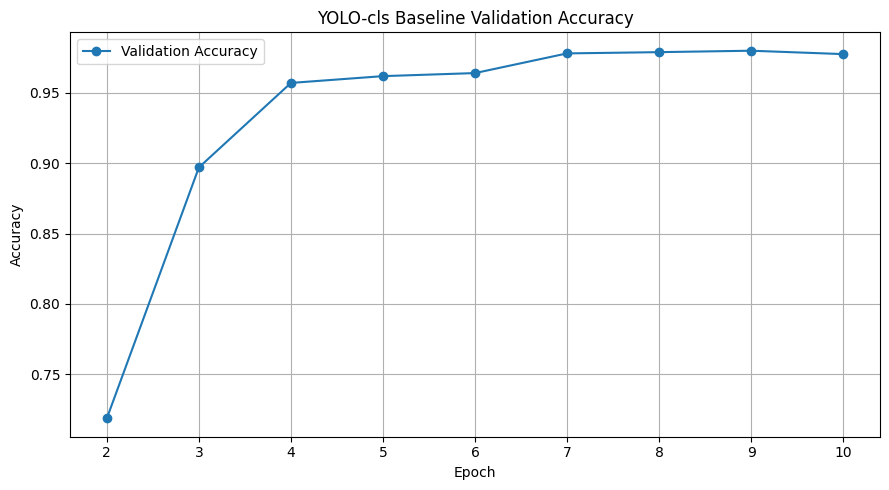

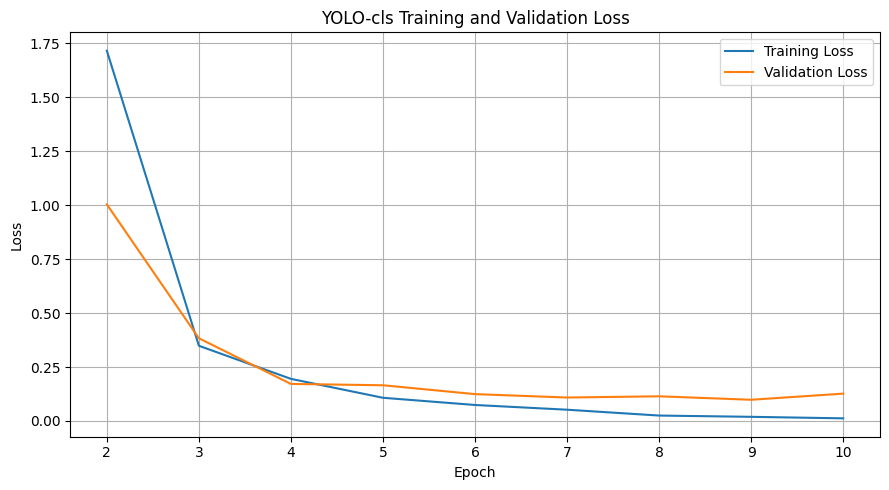

Best validation accuracy: 98.00%
Total epochs completed: 9


In [ ]:

# Load training history
results_csv = RUN_DIR / "results.csv"

assert results_csv.exists(), "Training results CSV not found!"

history = pd.read_csv(results_csv)
history.columns = history.columns.str.strip()

print("Available training metrics:")
print(history.columns.tolist())

# Epoch numbers
epochs = history["epoch"] + 1

# Find accuracy column
accuracy_column = "metrics/accuracy_top1"

assert accuracy_column in history.columns, (
    "Validation accuracy column not found!"
)

# Plot validation accuracy
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    history[accuracy_column],
    marker="o",
    label="Validation Accuracy"
)

plt.title("YOLO-cls Baseline Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# Plot training and validation loss
train_loss_column = "train/loss"
val_loss_column = "val/loss"

assert train_loss_column in history.columns
assert val_loss_column in history.columns

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    history[train_loss_column],
    label="Training Loss"
)

plt.plot(
    epochs,
    history[val_loss_column],
    label="Validation Loss"
)

plt.title("YOLO-cls Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# Display best validation accuracy
best_accuracy = history[accuracy_column].max()

print(f"Best validation accuracy: {best_accuracy * 100:.2f}%")
print(f"Total epochs completed: {len(history)}")


YOLO-cls Baseline Model Evaluation (Exploratory; final comparison uses tuned checkpoint)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 47 layers, 1,581,107 parameters, 0 gradients, 3.2 GFLOPs
train: /content/gtsrb_ready/train... found 31350 images in 43/43 classes ✅ 
val: /content/gtsrb_ready/val... found 7859 images in 43/43 classes ✅ 
test: /content/gtsrb_ready/test... found 12630 images in 43/43 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 842.3±277.6 MB/s, size: 22.1 KB)
test: Scanning /content/gtsrb_ready/test... 12630 images, 0 corrupt: 100% ━━━━━━━━━━━━ 12630/12630 5.5Kit/s 2.3s
test: New cache created: /content/gtsrb_ready/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 198/198 13.8it/s 14.4s
                   all      0.972      0.995
Speed: 0.0ms preprocess, 0.3ms inference, 0.0ms loss, 0.0ms postprocess per image


Exception in thread Thread-59 (_pin_memory_loop):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/pin_memory.py", line 52, in _pin_memory_loop
    do_one_step()
    ~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/pin_memory.py", line 28, in do_one_step
    r = in_queue.get(timeout=MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 120, in get
    return _ForkingPickler.loads(res)
           ~~~~~~~~~~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/multiprocessing/reductions.py", line 538, in rebuild_storage_fd
    fd = df.detach()
  File "/usr/lib/python3.13/multiprocessing/resourc


YOLO Baseline Official Test Evaluation
Top-1 Accuracy: 97.18%
Top-5 Accuracy: 99.51%

Detailed Test Metrics
Accuracy:  97.18%
Precision: 95.54%
Recall:    96.09%
Macro F1:  95.45%

Total prediction time: 20.91 seconds
Average time per image: 1.655 ms


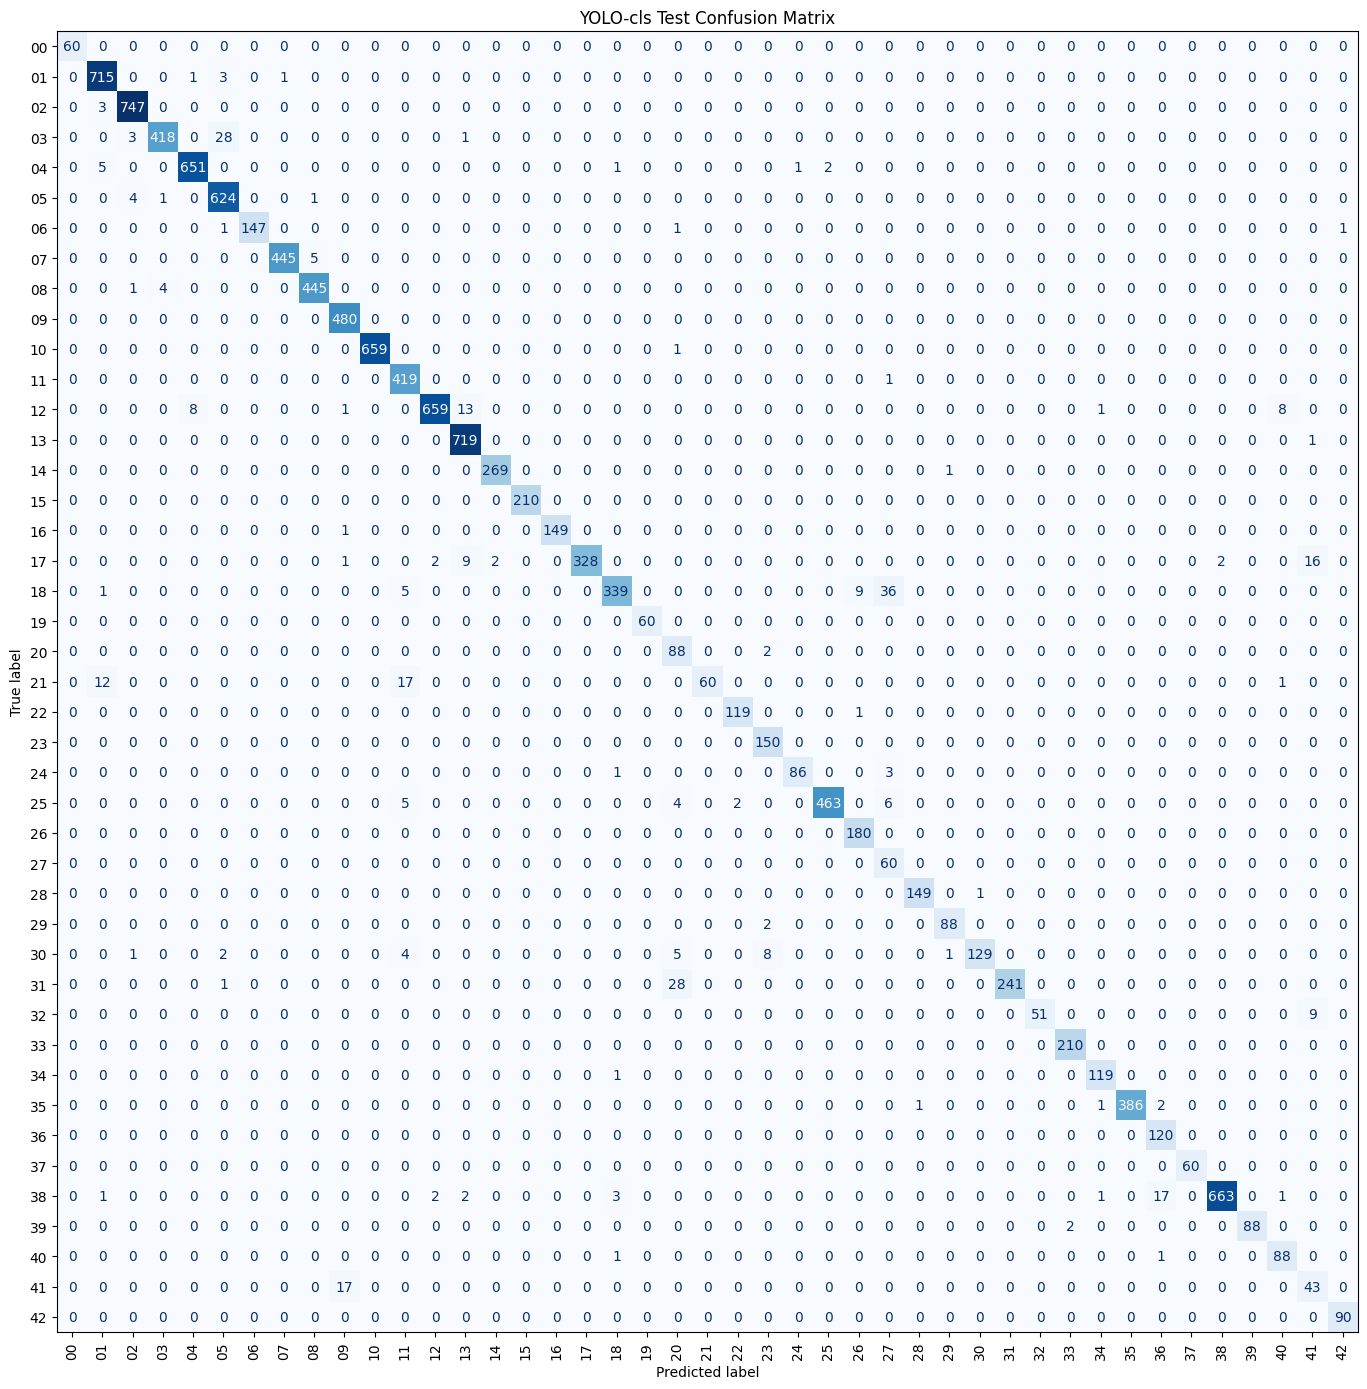


Classification Report:
              precision    recall  f1-score   support

          00       1.00      1.00      1.00        60
          01       0.97      0.99      0.98       720
          02       0.99      1.00      0.99       750
          03       0.99      0.93      0.96       450
          04       0.99      0.99      0.99       660
          05       0.95      0.99      0.97       630
          06       1.00      0.98      0.99       150
          07       1.00      0.99      0.99       450
          08       0.99      0.99      0.99       450
          09       0.96      1.00      0.98       480
          10       1.00      1.00      1.00       660
          11       0.93      1.00      0.96       420
          12       0.99      0.96      0.97       690
          13       0.97      1.00      0.98       720
          14       0.99      1.00      0.99       270
          15       1.00      1.00      1.00       210
          16       1.00      0.99      1.00       150
   

,Model,Initialization,Image Size,Number of Classes,Maximum Epochs,Completed Epochs,Batch Size,Seed,Training Time (seconds),Top-1 Accuracy,Top-5 Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Prediction Time (seconds)
0,YOLO26n-cls,From scratch,128,43,30,9,64,42,352.683811,0.971813,0.995091,0.955386,0.960855,0.954525,20.907845



YOLO-cls evaluation and saving completed!


In [ ]:
import gc
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Free up GPU memory before starting evaluation
gc.collect()
torch.cuda.empty_cache()

# Load best checkpoint
BEST_MODEL_PATH = RUN_DIR / "weights" / "best.pt"

assert BEST_MODEL_PATH.exists(), "Best YOLO checkpoint not found!"

best_yolo = YOLO(str(BEST_MODEL_PATH))

# Evaluate on official test set using YOLO's built-in validation
yolo_test_metrics = best_yolo.val(
    data=str(YOLO_DATASET),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    validator=GTSRBClassificationValidator,
    plots=False
)

# Top-1 and Top-5 accuracy
yolo_test_accuracy = yolo_test_metrics.top1
yolo_test_top5 = yolo_test_metrics.top5

print("\nYOLO Baseline Official Test Evaluation")
print(f"Top-1 Accuracy: {yolo_test_accuracy * 100:.2f}%")
print(f"Top-5 Accuracy: {yolo_test_top5 * 100:.2f}%")

# Prepare test images and their true labels
class_names = [f"{i:02d}" for i in range(NUM_CLASSES)]

test_images = []
y_true = []

for class_index, class_name in enumerate(class_names):
    class_folder = TEST_DIR / class_name
    image_paths = sorted([
        p for p in class_folder.rglob("*")
        if p.is_file() and p.suffix.lower() in valid_extensions
    ])
    test_images.extend(image_paths)
    y_true.extend([class_index] * len(image_paths))

# Generate predictions in batches to prevent Out Of Memory (OOM)
y_pred = []
prediction_start = time.time()

BATCH_SIZE_PRED = 512

# Enable torch.no_grad() for efficient inference
with torch.no_grad():
    for i in range(0, len(test_images), BATCH_SIZE_PRED):
        batch_paths = [str(p) for p in test_images[i:i + BATCH_SIZE_PRED]]
        # Run prediction on the current batch
        results = best_yolo.predict(
            source=batch_paths,
            imgsz=IMAGE_SIZE,
            device=DEVICE,
            verbose=False
        )
        for result in results:
            y_pred.append(result.probs.top1)

prediction_time = time.time() - prediction_start

# Calculate evaluation metrics
yolo_sk_accuracy = accuracy_score(y_true, y_pred)

test_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

test_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

test_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\nDetailed Test Metrics")
print(f"Accuracy:  {yolo_sk_accuracy * 100:.2f}%")
print(f"Precision: {test_precision * 100:.2f}%")
print(f"Recall:    {test_recall * 100:.2f}%")
print(f"Macro F1:  {test_f1 * 100:.2f}%")

print(f"\nTotal prediction time: {prediction_time:.2f} seconds")
print(f"Average time per image: {prediction_time / len(test_images) * 1000:.3f} ms")

# Generate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(16, 14))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    xticks_rotation="vertical",
    ax=plt.gca(),
    colorbar=False
)

plt.title("YOLO-cls Test Confusion Matrix")
plt.tight_layout()
plt.show()

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        zero_division=0
    )
)

# Save best model
SAVED_MODEL_PATH = Path("/content/best_yolo_cls.pt")
shutil.copy2(BEST_MODEL_PATH, SAVED_MODEL_PATH)
print("\nBest model saved to:", SAVED_MODEL_PATH)

# Save evaluation summary
yolo_summary = pd.DataFrame([{
    "Model": "YOLO26n-cls",
    "Initialization": "From scratch",
    "Image Size": IMAGE_SIZE,
    "Number of Classes": NUM_CLASSES,
    "Maximum Epochs": EPOCHS,
    "Completed Epochs": len(history),
    "Batch Size": BATCH_SIZE,
    "Seed": SEED,
    "Training Time (seconds)": yolo_training_time,
    "Top-1 Accuracy": yolo_test_accuracy,
    "Top-5 Accuracy": yolo_test_top5,
    "Precision (Macro)": test_precision,
    "Recall (Macro)": test_recall,
    "F1-Score (Macro)": test_f1,
    "Prediction Time (seconds)": prediction_time
}])

yolo_summary.to_csv(
    "/content/yolo_test_results.csv",
    index=False
)

print("\nEvaluation summary:")
display(yolo_summary)

print("\nYOLO-cls evaluation and saving completed!")

### YOLO-cls Hyper-parameter Search

In [ ]:
import gc, time, random, shutil, os
from pathlib import Path
import numpy as np, pandas as pd, torch
from ultralytics import YOLO

assert "GTSRBClassificationTrainer" in globals(), "Run the YOLO-cls Model Configuration cell first."

# ---------- speed knobs ----------
SEARCH_FRAC   = 0.25   # fraction of train/val images used for the search
SEARCH_EPOCHS = 4
SEARCH_IMGSZ  = 64     # final retrain stays at 128
SEARCH_DIR    = Path("/content/gtsrb_search")
RUNS_DIR      = "/content/runs/search_yolo"

# ---------- build stratified symlink subset (once) ----------
def build_subset(src_root, dst_root, frac, seed=SEED):
    rng = random.Random(seed)
    for split in ("train", "val"):
        for cls_dir in sorted((src_root / split).iterdir()):
            files = sorted(cls_dir.glob("*.png"))
            keep = rng.sample(files, max(1, int(len(files) * frac)))
            out = dst_root / split / cls_dir.name
            out.mkdir(parents=True, exist_ok=True)
            for f in keep:
                link = out / f.name
                if not link.exists():
                    os.symlink(f, link)

if SEARCH_DIR.exists():
    shutil.rmtree(SEARCH_DIR)
build_subset(READY_ROOT, SEARCH_DIR, SEARCH_FRAC)
print({s: sum(1 for _ in (SEARCH_DIR / s).rglob("*.png")) for s in ("train", "val")})

# ---------- one trial ----------
def run_yolo_trial(cfg, idx=[0]):
    gc.collect(); torch.cuda.empty_cache()
    model = train_with_fallback(
        lambda: YOLO("yolo26n-cls.yaml"),
        data=str(SEARCH_DIR), epochs=SEARCH_EPOCHS, imgsz=SEARCH_IMGSZ,   # equal epochs => fair comparison between trials
        batch=64, seed=SEED, deterministic=False,
        optimizer=cfg["optimizer"], lr0=cfg["lr0"],
        weight_decay=cfg["weight_decay"], dropout=cfg["dropout"],
        patience=SEARCH_EPOCHS, device=DEVICE,
        workers=min(4, os.cpu_count() or 2), cache="ram",
        project=RUNS_DIR, name=f"trial_{idx[0]:02d}", exist_ok=True,
        trainer=GTSRBClassificationTrainer,
        plots=False, val=True, verbose=False, save=False)
    idx[0] += 1
    hist = pd.read_csv(Path(model.trainer.save_dir) / "results.csv")
    hist.columns = hist.columns.str.strip()
    acc = float(hist["metrics/accuracy_top1"].max())
    del model; gc.collect()
    return acc

# ---------- reduced space, coordinate search with caching ----------
YOLO_BASELINE = {"lr0": 1e-3, "optimizer": "Adam", "weight_decay": 5e-4, "dropout": 0.0}
YOLO_SPACE = {
    "lr0":          [1e-2, 3e-3, 1e-3, 3e-4],        # 1e-4 dropped: too slow to converge in 4 epochs
    "optimizer":    ["Adam", "AdamW"],
    "weight_decay": [0.0, 5e-4, 5e-3],
    "dropout":      [0.0, 0.2],
}

def coordinate_search(space, baseline, run_fn):
    best, cache, log = baseline.copy(), {}, []
    def ev(cfg):
        k = tuple(sorted(cfg.items()))
        if k not in cache:
            cache[k] = run_fn(cfg.copy())
            log.append({**cfg, "val_accuracy": cache[k]})
            print(f"{cfg} -> {cache[k]:.4f}", flush=True)
        return cache[k]
    best_acc = ev(best)
    for param, values in space.items():
        scores = [(v, ev({**best, param: v})) for v in values]
        v, a = max(scores, key=lambda s: s[1])
        best[param], best_acc = v, a
        print(f"Best {param}: {v} ({a:.4f})\n")
    return best, best_acc, pd.DataFrame(log)

t0 = time.time()
yolo_best, yolo_best_val, yolo_search_results = coordinate_search(YOLO_SPACE, YOLO_BASELINE, run_yolo_trial)
yolo_search_time = time.time() - t0

yolo_search_results.to_csv("/content/yolo_search_results.csv", index=False)
print("Best:", yolo_best, f"| val acc {yolo_best_val:.4f} | search time {yolo_search_time/60:.1f} min")

{'train': 7830, 'val': 1954}
YOLO26n-cls summary: 86 layers, 2,812,104 parameters, 2,812,104 gradients, 3.3 GFLOPs
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/gtsrb_search, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=64, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.yaml

YOLO-cls: Accuracy vs. Parameter Plots & Optimum Parameters Table

,parameter,value,val_accuracy
0,lr0,0.01,0.57165
1,lr0,0.003,0.77687
2,lr0,0.001,0.70573
3,lr0,0.0003,0.63153
4,optimizer,Adam,0.77687
5,optimizer,AdamW,0.80450
6,weight_decay,0.0,0.83572
7,weight_decay,0.0005,0.80450
8,weight_decay,0.005,0.79785
9,dropout,0.0,0.83572


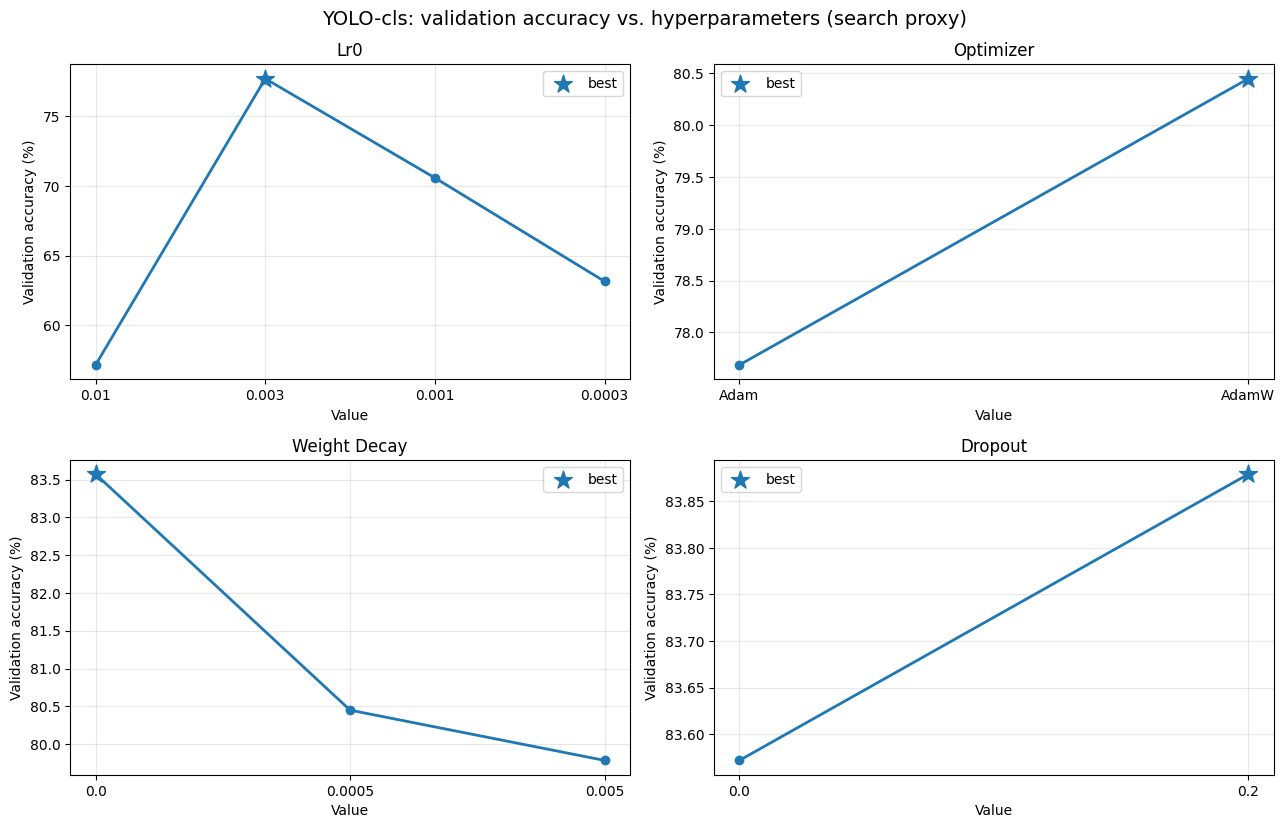

,Model,lr0,optimizer,weight_decay,dropout,Search Val Accuracy (%)
0,YOLO-cls,0.003,AdamW,0.0,0.2,83.879


In [ ]:
import matplotlib.pyplot as plt

def replay_stage_log(results, space, baseline):
    """Rebuild the per-stage log from the saved trials (no retraining)."""
    keys = list(space)
    acc = {tuple(r[k] for k in keys): r["val_accuracy"] for r in results.to_dict("records")}
    best, log = baseline.copy(), []
    for p, values in space.items():
        scores = []
        for v in values:
            cfg = {**best, p: v}
            a = acc[tuple(cfg[k] for k in keys)]
            log.append({"parameter": p, "value": v, "val_accuracy": a})
            scores.append((v, a))
        best[p] = max(scores, key=lambda s: s[1])[0]
    return best, pd.DataFrame(log)

def plot_search(log, model_name, space):
    """Validation accuracy vs. each searched parameter (one panel per parameter)."""
    params = list(space)
    cols = 2
    rows = int(np.ceil(len(params) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(13, 4.2 * rows))
    axes = np.atleast_1d(axes).flatten()

    for ax, p in zip(axes, params):
        sub = log[log["parameter"] == p].copy()
        sub["order"] = sub["value"].map(lambda v: space[p].index(v))
        sub = sub.sort_values("order")
        labels = sub["value"].astype(str).tolist()
        acc = (sub["val_accuracy"] * 100).tolist()

        ax.plot(labels, acc, marker="o", linewidth=2)
        top = int(np.argmax(acc))
        ax.scatter([labels[top]], [acc[top]], s=180, marker="*", zorder=3, label="best")
        ax.set_title(p.replace("_", " ").title())
        ax.set_xlabel("Value")
        ax.set_ylabel("Validation accuracy (%)")
        ax.grid(True, alpha=0.3)
        ax.legend()

    for ax in axes[len(params):]:
        ax.axis("off")

    plt.suptitle(f"{model_name}: validation accuracy vs. hyperparameters (search proxy)", fontsize=14)
    plt.tight_layout()
    plt.show()

def best_params_table(best, best_val, model_name):
    df = pd.DataFrame([best])
    df.insert(0, "Model", model_name)
    df["Search Val Accuracy (%)"] = best_val * 100
    return df

# Rebuild the stage log from the trials you already ran
replayed_best, yolo_search_log = replay_stage_log(yolo_search_results, YOLO_SPACE, YOLO_BASELINE)
assert replayed_best == yolo_best, (replayed_best, yolo_best)   # must match the search's choice
yolo_search_log.to_csv("/content/yolo_search_log.csv", index=False)
display(yolo_search_log)                                         # expect 12 rows

plot_search(yolo_search_log, "YOLO-cls", YOLO_SPACE)

yolo_params_table = best_params_table(yolo_best, yolo_best_val, "YOLO-cls")
display(yolo_params_table)
yolo_params_table.to_csv("/content/yolo_optimum_parameters.csv", index=False)

YOLO-cls: Retrain with Optimum Parameters (full budget)

In [ ]:
import gc
import torch
import time
import shutil
import os
import math
from pathlib import Path
import torch.nn.functional as F
import torchvision.transforms as T
from ultralytics import YOLO
from ultralytics.data.dataset import ClassificationDataset
from ultralytics.models.yolo.classify import ClassificationTrainer

# Configure all missing variables locally to make this cell completely robust
SEED = 42
IMG = 128
BATCH_SIZE = 64
DEVICE = 0 if torch.cuda.is_available() else "cpu"
READY_ROOT = Path("/content/gtsrb_ready")
YOLO_TUNED_MIN = 4.5
DATA_SIZE = 128
AUG_MODE = "gpu"

# Use the parameters actually selected by the preceding YOLO coordinate search.
assert "yolo_best" in globals(), "Run the YOLO hyperparameter-search cell first."
assert isinstance(yolo_best, dict) and all(k in yolo_best for k in ("lr0", "optimizer", "weight_decay", "dropout"))

def gpu_augment(x, deg=18.0, trans=0.05, scale=(0.9, 1.1), contrast=0.1):
    """Same ranges as the original CPU pipeline (rotation +-18 deg, translation +-5%, scale 0.9-1.1,
    contrast +-10%), applied to a whole batch on the GPU. x: float tensor [B,3,H,W] in [0,1]."""
    x = x.float(); B = x.shape[0]; d = x.device
    ang = (torch.rand(B, device=d) * 2 - 1) * deg * math.pi / 180.0
    sc = torch.empty(B, device=d).uniform_(scale[0], scale[1])
    tx = (torch.rand(B, device=d) * 2 - 1) * trans * 2
    ty = (torch.rand(B, device=d) * 2 - 1) * trans * 2
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    f = torch.empty(B, 1, 1, 1, device=d).uniform_(1 - contrast, 1 + contrast)
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    return ((x - m) * f + m).clamp_(0, 1)

class GTSRBClassificationDataset(ClassificationDataset):
    def __init__(self, root, args, augment=False, prefix="", names=None):
        super().__init__(root, args, augment, prefix, names)
        s_ = int(args.imgsz)
        pre = [T.Resize((s_, s_))] if s_ != DATA_SIZE else []
        if augment and AUG_MODE == "cpu":
            self.torch_transforms = T.Compose(pre + [
                T.RandomAffine(degrees=18, translate=(0.05, 0.05), scale=(0.9, 1.1)),
                T.ColorJitter(contrast=0.1), T.ToTensor()])
        else:
            self.torch_transforms = T.Compose(pre + [T.ToTensor()])

class GTSRBClassificationTrainer(ClassificationTrainer):
    def build_dataset(self, img_path, mode="train", batch=None):
        return GTSRBClassificationDataset(
            root=img_path, args=self.args, augment=(mode == "train"),
            prefix="train" if mode == "train" else self.args.split, names=self.data["names"])

    def preprocess_batch(self, batch):
        batch = super().preprocess_batch(batch)
        if AUG_MODE == "gpu" and self.model.training:
            batch["img"] = gpu_augment(batch["img"])
        return batch

def train_with_fallback(model_ctor, **kw):
    """Train; if the GPU-augmentation path raises, retry once with the original CPU augmentation."""
    global AUG_MODE
    model = model_ctor()
    try:
        model.train(**kw)
        return model
    except Exception as e:
        if AUG_MODE != "gpu":
            raise
        print("\nGPU-augmentation path failed:", repr(e)[:300], "\n-> falling back to CPU augmentation")
        AUG_MODE = "cpu"; gc.collect(); torch.cuda.empty_cache()
        model = model_ctor(); model.train(**kw)
        return model

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

t0 = time.time()
tuned_yolo = train_with_fallback(
    lambda: YOLO("yolo26n-cls.yaml"),
    data=str(READY_ROOT), epochs=30, time=YOLO_TUNED_MIN / 60.0, imgsz=IMG,
    batch=BATCH_SIZE, seed=SEED, deterministic=False,
    optimizer=yolo_best["optimizer"], lr0=yolo_best["lr0"],
    weight_decay=yolo_best["weight_decay"], dropout=yolo_best["dropout"],
    patience=5, device=DEVICE, workers=min(4, os.cpu_count() or 2), cache="ram",
    project="/content/runs/classify", name="gtsrb_yolo_tuned", exist_ok=True,
    trainer=GTSRBClassificationTrainer, plots=False, val=True)
tuned_yolo_training_time = time.time() - t0

TUNED_RUN_DIR = Path(tuned_yolo.trainer.save_dir)
shutil.copy2(TUNED_RUN_DIR / "weights" / "best.pt", "/content/best_yolo_cls_tuned.pt")
print(f"Augmentation used: {AUG_MODE}")
print(f"Tuned YOLO-cls training time: {tuned_yolo_training_time:.1f} s")

YOLO26n-cls summary: 86 layers, 2,812,104 parameters, 2,812,104 gradients, 3.3 GFLOPs
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/gtsrb_ready, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.2, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=128, iou=None, kobj=1.0, line_width=None, lr0=0.003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.yaml, momentum=0.937, mosaic=1.0

Optimization Summary (Baseline vs. Tuned, Validation Accuracy)

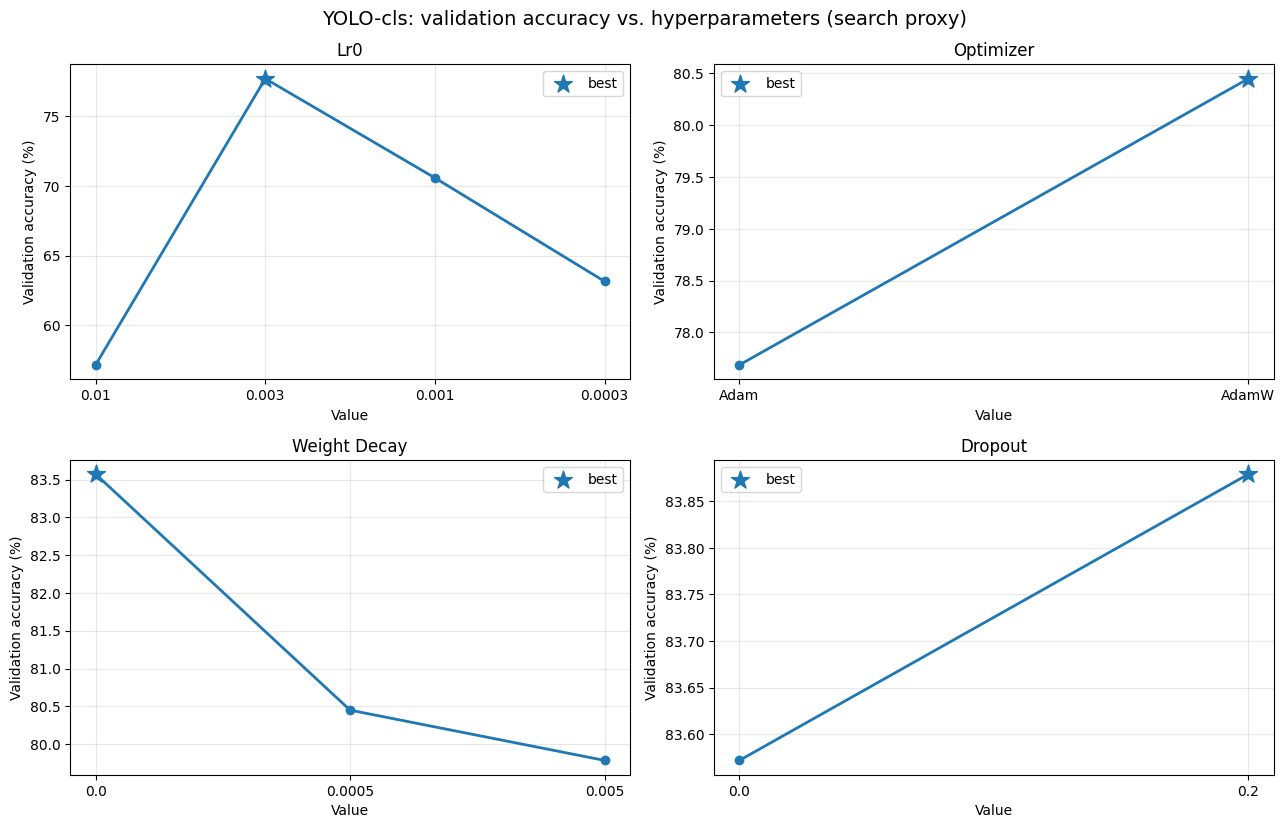

,lr0,optimizer,weight_decay,dropout,Best Validation Accuracy (%),Search Trials,Search Time (seconds)
0,0.003,AdamW,0.0,0.2,83.879,8,393.389114


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

yolo_optimum_path = Path("/content/yolo_optimum_parameters.csv")

YOLO_BASELINE = {"lr0": 1e-3, "optimizer": "Adam", "weight_decay": 5e-4, "dropout": 0.0}
YOLO_SPACE = {
    "lr0":          [1e-2, 3e-3, 1e-3, 3e-4],
    "optimizer":    ["Adam", "AdamW"],
    "weight_decay": [0.0, 5e-4, 5e-3],
    "dropout":      [0.0, 0.2],
}

def replay_stage_log(results, space, baseline):
    """Rebuild the per-stage log from the saved trials (no retraining)."""
    keys = list(space)
    acc = {tuple(r[k] for k in keys): r["val_accuracy"] for r in results.to_dict("records")}
    best, log = baseline.copy(), []
    for p, values in space.items():
        scores = []
        for v in values:
            cfg = {**best, p: v}
            a = acc[tuple(cfg[k] for k in keys)]
            log.append({"parameter": p, "value": v, "val_accuracy": a})
            scores.append((v, a))
        best[p] = max(scores, key=lambda s: s[1])[0]
    return best, pd.DataFrame(log)

def plot_search(log, model_name, space):
    """Validation accuracy vs. each searched parameter (one panel per parameter)."""
    params = list(space)
    cols = 2
    rows = int(np.ceil(len(params) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(13, 4.2 * rows))
    axes = np.atleast_1d(axes).flatten()

    for ax, p in zip(axes, params):
        sub = log[log["parameter"] == p].copy()
        sub["order"] = sub["value"].map(lambda v: space[p].index(v) if v in space[p] else 0)
        sub = sub.sort_values("order")
        labels = sub["value"].astype(str).tolist()
        acc = (sub["val_accuracy"] * 100).tolist()

        ax.plot(labels, acc, marker="o", linewidth=2)
        top = int(np.argmax(acc))
        ax.scatter([labels[top]], [acc[top]], s=180, marker="*", zorder=3, label="best")
        ax.set_title(p.replace("_", " ").title())
        ax.set_xlabel("Value")
        ax.set_ylabel("Validation accuracy (%)")
        ax.grid(True, alpha=0.3)
        ax.legend()

    for ax in axes[len(params):]:
        ax.axis("off")

    plt.suptitle(f"{model_name}: validation accuracy vs. hyperparameters (search proxy)", fontsize=14)
    plt.tight_layout()
    plt.show()

# Always visualize the current search results from this notebook run.
assert "yolo_search_results" in globals(), "Run the YOLO search cell first."

# Safely rebuild/retrieve the stage log from the trial results
_, yolo_search_log = replay_stage_log(yolo_search_results, YOLO_SPACE, YOLO_BASELINE)

plot_search(yolo_search_log, "YOLO-cls", YOLO_SPACE)
yolo_params_table = pd.DataFrame([yolo_best])
yolo_params_table["Best Validation Accuracy (%)"] = yolo_best_val * 100
yolo_params_table["Search Trials"] = len(yolo_search_results)
yolo_params_table["Search Time (seconds)"] = yolo_search_time
display(yolo_params_table)

### 6.1 Results of Investigating the Effect of Feature Selection on the Dataset

This section investigates **correlation-based feature ranking and selection** using 15 handcrafted RGB color-statistical features: the mean, standard deviation, median, 10th percentile, and 90th percentile of each color channel.

Features are ranked by their mean absolute Pearson correlation with one-vs-rest class indicators. Five subset sizes (15, 8, 4, 2, and 1) are evaluated with Linear SVM, Random Forest, and KNN. Evaluation uses 10-fold stratified group cross-validation on the combined training and validation sets, with traffic sign tracks used as groups. Feature rankings are recalculated using only the training portion of each fold.

For each classifier, the feature subset with the highest mean cross-validation macro-F1 (accuracy as a secondary criterion) is selected. The final models are trained on the development data and evaluated on the held-out test set.

**Methodological clarification:** This is a correlation-based *filter* method, **not** conventional Recursive Feature Elimination (RFE). The held-out test set is not used to choose the feature subsets.


In [ ]:
# ===== 6.1 Correlation-Based Feature Ranking and Selection (15 -> 8 -> 4 -> 2 -> 1) =====
# 10-fold stratified GROUP cross-validation (groups = sign tracks) on train + val images only; test set used once.
import cv2, time, warnings, hashlib, numpy as np, pandas as pd
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
warnings.filterwarnings("ignore")

# Top-level helper for multiprocessing (ProcessPoolExecutor requires top-level functions)
def _extract_single_image(args):
    rel_path, root_str = args
    img = cv2.imread(str(Path(root_str) / rel_path))
    if img is None:
        raise FileNotFoundError(f"Could not read image: {Path(root_str) / rel_path}")
    # Downsample every 2nd pixel (4x faster) and convert BGR -> RGB
    im = img[::2, ::2, ::-1].reshape(-1, 3).astype(np.float32) / 255.0
    p = np.percentile(im, [10, 50, 90], axis=0)
    return np.stack([im.mean(0), im.std(0), p[1], p[0], p[2]], axis=1).ravel()

def run_feature_selection_6_1():
    """Correlation-based feature ranking with grouped cross-validation."""
    T0 = time.time()
    ROOT = Path(READY_ROOT)
    OUT = Path("/content/rfe_results")
    OUT.mkdir(exist_ok=True)

    # 1. Load manifest and filter for development data (train + val)
    allm = pd.read_csv(ROOT / "split_manifest.csv")
    man = allm[allm["split"].isin(["train", "val"])].reset_index(drop=True)
    y, groups = man["ClassId"].to_numpy(), man["track_id"].astype(str).to_numpy()

    NAMES = [f"{c}_{s}" for c in "RGB" for s in ("mean", "std", "median", "p10", "p90")]
    # Cache rows include image identifiers and a source-file fingerprint.
    # Old feature-only caches are automatically rebuilt rather than silently reused.
    def source_fingerprints(manifest):
        fingerprints = []
        for rel_path in manifest["output_path"].astype(str):
            path = ROOT / rel_path
            stat = path.stat()
            signature = f"{rel_path}|{stat.st_size}|{stat.st_mtime_ns}"
            fingerprints.append(hashlib.sha256(signature.encode("utf-8")).hexdigest())
        return fingerprints

    def load_or_extract_features(manifest, cache_path):
        paths = manifest["output_path"].astype(str).tolist()
        labels = manifest["ClassId"].to_numpy()
        fingerprints = source_fingerprints(manifest)
        if cache_path.exists():
            cached = pd.read_csv(cache_path)
            required = {"output_path", "ClassId", "source_fingerprint", *NAMES}
            if required.issubset(cached.columns):
                valid = (
                    len(cached) == len(paths)
                    and cached["output_path"].astype(str).tolist() == paths
                    and np.array_equal(cached["ClassId"].to_numpy(), labels)
                    and cached["source_fingerprint"].astype(str).tolist() == fingerprints
                    and np.isfinite(cached[NAMES].to_numpy(dtype=float)).all()
                )
                if valid:
                    print(f"Using validated feature cache: {cache_path}")
                    return cached[NAMES].copy()
            print(f"Cache outdated or incompatible; rebuilding: {cache_path}")

        tasks = [(path, str(ROOT)) for path in paths]
        print(f"Extracting features for {len(tasks):,} images using multiprocessing...")
        with ProcessPoolExecutor() as ex:
            features_list = list(ex.map(_extract_single_image, tasks, chunksize=256))
        features = pd.DataFrame(features_list, columns=NAMES)
        saved = features.copy()
        saved.insert(0, "source_fingerprint", fingerprints)
        saved.insert(0, "ClassId", labels)
        saved.insert(0, "output_path", paths)
        saved.to_csv(cache_path, index=False)
        return features

    cache = OUT / "extracted_features.csv"
    X = load_or_extract_features(man, cache)
    print(f"Features ready: {X.shape} in {time.time() - T0:.1f}s")

    # 3. Vectorized Pearson correlation ranking (optimized with contiguous float32 arrays)
    def rank(Xd, yd):
        Xd = np.ascontiguousarray(Xd, dtype=np.float32)
        Z = (Xd - Xd.mean(axis=0)) / (Xd.std(axis=0) + 1e-12)
        Y = (yd[:, None] == np.unique(yd)[None]).astype(np.float32)
        Y = (Y - Y.mean(axis=0)) / (Y.std(axis=0) + 1e-12)
        return np.abs(Z.T @ Y / len(yd)).mean(axis=1)

    sizes = [15, 8, 4, 2, 1]
    classifiers = ("Linear SVM", "Random Forest", "KNN")

    def get_model(name):
        if name == "Linear SVM":
            return make_pipeline(StandardScaler(), LinearSVC(C=1.0, dual=False, class_weight="balanced", max_iter=2000))
        elif name == "Random Forest":
            return RandomForestClassifier(n_estimators=60, max_samples=0.5, min_samples_leaf=2,
                                          class_weight="balanced_subsample", n_jobs=-1, random_state=42)
        elif name == "KNN":
            return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1))

    # 4. 10-Fold Stratified Group CV with dynamic re-ranking per fold
    rows, Xv = [], X.to_numpy(dtype=np.float32)
    cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

    for k, (tr, va) in enumerate(cv.split(Xv, y, groups), 1):
        order = np.argsort(-rank(Xv[tr], y[tr]))
        for n in sizes:
            cols = order[:n]
            for name in classifiers:
                clf = get_model(name)
                preds = clf.fit(Xv[tr][:, cols], y[tr]).predict(Xv[va][:, cols])
                rows.append({
                    "Fold": k, "Classifier": name, "Features": n,
                    "Accuracy": accuracy_score(y[va], preds),
                    "Macro F1": f1_score(y[va], preds, average="macro", zero_division=0)
                })
        print(f"Fold {k}/10 complete ({time.time() - T0:.1f}s elapsed)")

    cv_df = pd.DataFrame(rows)
    cv_df.to_csv(OUT / "feature_selection_fold_results.csv", index=False)

    # 5. Aggregate metrics & format Table 6.1
    g = cv_df.groupby(["Classifier", "Features"]).agg(
        Acc=("Accuracy", "mean"), AccSD=("Accuracy", "std"),
        F1=("Macro F1", "mean"), F1SD=("Macro F1", "std")
    ).fillna(0) * 100

    tab = pd.DataFrame({"Features used": ["All (15)", "Best 8", "Best 4", "Best 2", "Best 1"]}, index=sizes)
    for c in classifiers:
        tab[f"{c} Accuracy (%)"] = [f"{g.loc[(c, n), 'Acc']:.2f} ± {g.loc[(c, n), 'AccSD']:.2f}" for n in sizes]
        tab[f"{c} Macro-F1 (%)"] = [f"{g.loc[(c, n), 'F1']:.2f} ± {g.loc[(c, n), 'F1SD']:.2f}" for n in sizes]

    display(tab)
    tab.to_csv(OUT / "table_6_1_feature_selection.csv")

    # 6. Final evaluation on the held-out test set
    final_ranking = np.argsort(-rank(Xv, y))
    print("\nFinal feature ranking (best first):", [NAMES[i] for i in final_ranking])
    te = allm[allm["split"] == "test"].reset_index(drop=True)
    tc = OUT / "extracted_test_features.csv"

    Xt = load_or_extract_features(te, tc).to_numpy(dtype=np.float32)

    yt, final_results = te["ClassId"].to_numpy(), []
    for c in classifiers:
        best_n = g.loc[c].sort_values(["F1", "Acc"], ascending=False).index[0]
        cols = final_ranking[:best_n]
        preds = get_model(c).fit(Xv[:, cols], y).predict(Xt[:, cols])
        final_results.append({
            "Classifier": c, "Selected features": best_n,
            "Which": ", ".join(NAMES[i] for i in cols),
            "CV macro-F1 (%)": g.loc[(c, best_n), "F1"],
            "Test accuracy (%)": 100 * accuracy_score(yt, preds),
            "Test macro-F1 (%)": 100 * f1_score(yt, preds, average="macro", zero_division=0)
        })

    final_df = pd.DataFrame(final_results)
    display(final_df.round(2))
    final_df.to_csv(OUT / "feature_selection_final_models.csv", index=False)
    print(f"Total execution time: {(time.time() - T0) / 60:.1f} minutes")

run_feature_selection_6_1()

Extracting features for 39,209 images using multiprocessing...
Features ready: (39209, 15) in 57.2s
Fold 1/10 complete (86.1s elapsed)
Fold 2/10 complete (114.5s elapsed)
Fold 3/10 complete (141.0s elapsed)
Fold 4/10 complete (167.3s elapsed)
Fold 5/10 complete (195.7s elapsed)
Fold 6/10 complete (223.7s elapsed)
Fold 7/10 complete (252.1s elapsed)
Fold 8/10 complete (280.0s elapsed)
Fold 9/10 complete (307.3s elapsed)
Fold 10/10 complete (334.9s elapsed)


,Features used,Linear SVM Accuracy (%),Linear SVM Macro-F1 (%),Random Forest Accuracy (%),Random Forest Macro-F1 (%),KNN Accuracy (%),KNN Macro-F1 (%)
15,All (15),8.51 ± 1.55,5.50 ± 0.81,13.30 ± 1.71,9.08 ± 1.28,12.07 ± 1.66,8.47 ± 1.43
8,Best 8,7.48 ± 1.21,4.62 ± 0.47,11.31 ± 1.34,7.60 ± 1.12,10.72 ± 1.56,7.19 ± 1.46
4,Best 4,4.98 ± 0.97,2.47 ± 0.64,8.75 ± 1.26,5.80 ± 0.69,8.90 ± 1.67,5.63 ± 0.86
2,Best 2,4.33 ± 1.65,1.36 ± 0.55,4.90 ± 1.42,3.47 ± 0.79,5.59 ± 0.98,3.42 ± 0.61
1,Best 1,3.82 ± 1.33,0.83 ± 0.21,3.26 ± 0.33,2.57 ± 0.25,4.22 ± 0.38,2.54 ± 0.19



Final feature ranking (best first): ['B_mean', 'B_median', 'R_mean', 'R_median', 'G_mean', 'R_p90', 'G_p90', 'B_p90', 'G_median', 'R_std', 'G_std', 'B_p10', 'B_std', 'G_p10', 'R_p10']
Extracting features for 12,630 images using multiprocessing...


,Classifier,Selected features,Which,CV macro-F1 (%),Test accuracy (%),Test macro-F1 (%)
0,Linear SVM,15,"B_mean, B_median, R_mean, R_median, G_mean, R_...",5.50,8.68,5.89
1,Random Forest,15,"B_mean, B_median, R_mean, R_median, G_mean, R_...",9.08,13.37,9.90
2,KNN,15,"B_mean, B_median, R_mean, R_median, G_mean, R_...",8.47,12.68,9.96


Total execution time: 6.1 minutes


## 3. Evaluation and Analysis


**A. Evaluation**

In [ ]:
import gc, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import torch
from PIL import Image, ImageFilter
from tqdm.auto import tqdm
from ultralytics import YOLO
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

SEED = 42
IMG = 128
NUM_CLASSES = 43
DEVICE = 0 if torch.cuda.is_available() else "cpu"

# Let TensorFlow and PyTorch share the GPU (wrapped in a try-except to avoid initialization errors)
try:
    for _g in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(_g, True)
except RuntimeError as e:
    print("TensorFlow memory growth configuration skipped:", e)

READY_ROOT = Path("/content/gtsrb_ready")
TEST_DIR = READY_ROOT / "test"
class_names = [f"{i:02d}" for i in range(NUM_CLASSES)]

# ---- Test images (same sorted order for both models) ----
test_paths, y_true = [], []
for idx, name in enumerate(class_names):
    files = sorted((TEST_DIR / name).glob("*.png"))
    test_paths += files
    y_true += [idx] * len(files)

y_true = np.array(y_true)
X_test = np.stack([
    np.array(Image.open(p).convert("RGB"))
    for p in tqdm(test_paths, desc="Loading test images")
])
print("Test images:", X_test.shape, X_test.dtype)

# ---- Best checkpoints (fail loudly instead of silently using baseline weights) ----
CNN_PATH  = Path("/content/best_cnn_tuned.keras")
YOLO_PATH = Path("/content/best_yolo_cls_tuned.pt")

assert CNN_PATH.exists(),  f"Missing {CNN_PATH} - run the tuned CNN retrain first."
assert YOLO_PATH.exists(), f"Missing {YOLO_PATH} - run the tuned YOLO retrain first."

best_cnn = tf.keras.models.load_model(CNN_PATH)
best_yolo = YOLO(str(YOLO_PATH))

# ---- Prediction helpers (return class probabilities) ----
def predict_cnn(X, bs=128):
    out = []
    for i in range(0, len(X), bs):
        batch = X[i:i + bs].astype("float32")      # Rescaling is inside the model
        out.append(np.asarray(best_cnn.predict_on_batch(batch)))
    return np.concatenate(out)

def predict_yolo(X, bs=128):
    out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            # Ultralytics treats numpy input as BGR (same as cv2.imread on files)
            batch = [np.ascontiguousarray(im[..., ::-1]) for im in X[i:i + bs]]
            res = best_yolo.predict(
                source=batch, imgsz=IMG, device=DEVICE, verbose=False
            )
            out.extend(r.probs.data.cpu().numpy() for r in res)
    return np.stack(out)

MODELS = {"CNN": predict_cnn, "YOLO-cls": predict_yolo}

TensorFlow memory growth configuration skipped: Physical devices cannot be modified after being initialized


Loading test images:   0%|          | 0/12630 [00:00<?, ?it/s]

Test images: (12630, 128, 128, 3) uint8


**Clean Test Set: Predictions & Inference Time**

In [ ]:
# Warm-up (excluded from timing)
for fn in MODELS.values():
    fn(X_test[:128])

clean_probs, infer_time = {}, {}

for name, fn in MODELS.items():
    gc.collect()
    t0 = time.time()
    clean_probs[name] = fn(X_test)
    infer_time[name] = time.time() - t0
    print(f"{name}: {infer_time[name]:.2f} s total | "
          f"{infer_time[name] / len(X_test) * 1000:.3f} ms/image")

CNN: 7.09 s total | 0.562 ms/image
YOLO-cls: 7.75 s total | 0.613 ms/image


**Note on inference-time measurement.** Timing is measured on the shared clean test images that are already loaded as in-memory arrays, after a 128-image warm-up that is excluded from the timing. It covers each model's prediction function (model forward pass and the model-specific input conversion inside that function) and **does not include** reading image files from disk or the dataset-level preprocessing (RGB conversion and letterboxing), which was applied once beforehand and is identical for both models. Batch size and hardware are the same for both models, but the two frameworks (Keras and Ultralytics) differ internally, so the times should be treated as an implementation-specific estimate, not a pure architectural comparison.

**Clean Test Set: Metrics Comparison**

In [ ]:
def top_k_accuracy(probs, y, k):
    topk = np.argsort(probs, axis=1)[:, -k:]
    return float((topk == y[:, None]).any(axis=1).mean())

def count_params(name):
    if name == "CNN":
        return best_cnn.count_params()
    # as loaded by Ultralytics (Conv+BN may be fused, so this can be < the unfused count)
    return sum(p.numel() for p in best_yolo.model.parameters())

# Sanity check: the numpy prediction path must reproduce the Keras evaluation from Section 2
_cnn_acc = float((clean_probs["CNN"].argmax(1) == y_true).mean())
assert abs(_cnn_acc - tuned_test_accuracy) < 5e-3, (
    f"CNN accuracy via predict path ({_cnn_acc:.4f}) != Keras evaluate "
    f"({tuned_test_accuracy:.4f}): check image order / preprocessing")

# Training time of the TUNED models being evaluated here
train_times = {"CNN": tuned_cnn_training_time, "YOLO-cls": tuned_yolo_training_time}
model_files = {"CNN": CNN_PATH, "YOLO-cls": YOLO_PATH}

rows = []
for name, probs in clean_probs.items():
    y_pred = probs.argmax(axis=1)
    p_m, r_m, f_m, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    _, _, f_w, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0)
    n_params = count_params(name)

    rows.append({
        "Model": name,
        "Top-1 Accuracy": float((y_pred == y_true).mean()),
        "Top-5 Accuracy": top_k_accuracy(probs, y_true, 5),
        "Precision (Macro)": p_m,
        "Recall (Macro)": r_m,
        "F1 (Macro)": f_m,
        "F1 (Weighted)": f_w,
        "Parameters": n_params,
        "Weights FP32 (MB)": n_params * 4 / 1e6,                          # comparable across frameworks
        "Checkpoint File (MB)": model_files[name].stat().st_size / 1e6,   # format-dependent
        "Training Time (s)": train_times[name],
        "Inference Total (s)": infer_time[name],
        "Inference (ms/img)": infer_time[name] / len(X_test) * 1000,
    })

comparison_df = pd.DataFrame(rows).set_index("Model")
display(comparison_df.style.format({
    "Top-1 Accuracy": "{:.4f}", "Top-5 Accuracy": "{:.4f}",
    "Precision (Macro)": "{:.4f}", "Recall (Macro)": "{:.4f}",
    "F1 (Macro)": "{:.4f}", "F1 (Weighted)": "{:.4f}",
    "Parameters": "{:,.0f}", "Weights FP32 (MB)": "{:.2f}", "Checkpoint File (MB)": "{:.2f}",
    "Training Time (s)": "{:.1f}", "Inference Total (s)": "{:.2f}",
    "Inference (ms/img)": "{:.3f}",
}, na_rep="n/a"))

comparison_df.to_csv("/content/model_comparison.csv")

,Top-1 Accuracy,Top-5 Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),F1 (Weighted),Parameters,Weights FP32 (MB),Checkpoint File (MB),Training Time (s),Inference Total (s),Inference (ms/img)
Model,,,,,,,,,,,,
CNN,0.9817,0.9971,0.9650,0.9657,0.9648,0.9815,"11,208,171",44.83,134.73,1446.4,7.09,0.562
YOLO-cls,0.9814,0.9971,0.9717,0.9817,0.9756,0.9816,"1,586,187",6.34,3.29,328.8,7.75,0.613


**Clean Test Set: Confusion Matrices**

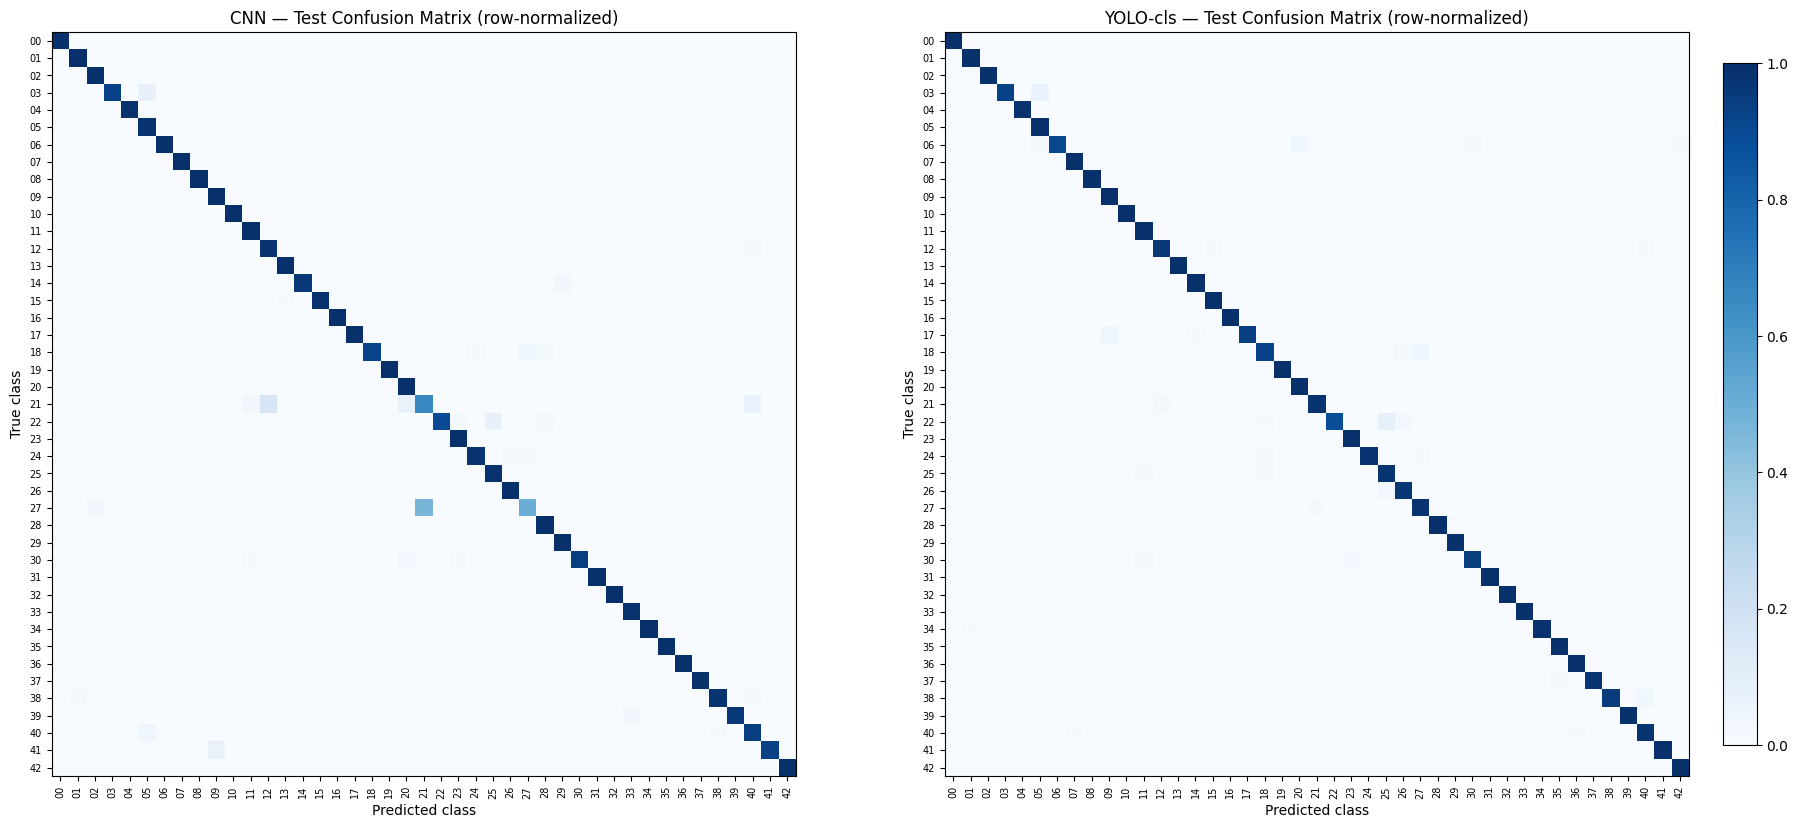

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(22, 10))

for ax, (name, probs) in zip(axes, clean_probs.items()):
    cm = confusion_matrix(y_true, probs.argmax(1), labels=range(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{name} — Test Confusion Matrix (row-normalized)")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(class_names, rotation=90, fontsize=7)
    ax.set_yticklabels(class_names, fontsize=7)

fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
plt.show()

**Clean Test Set: Multiclass ROC Curves**

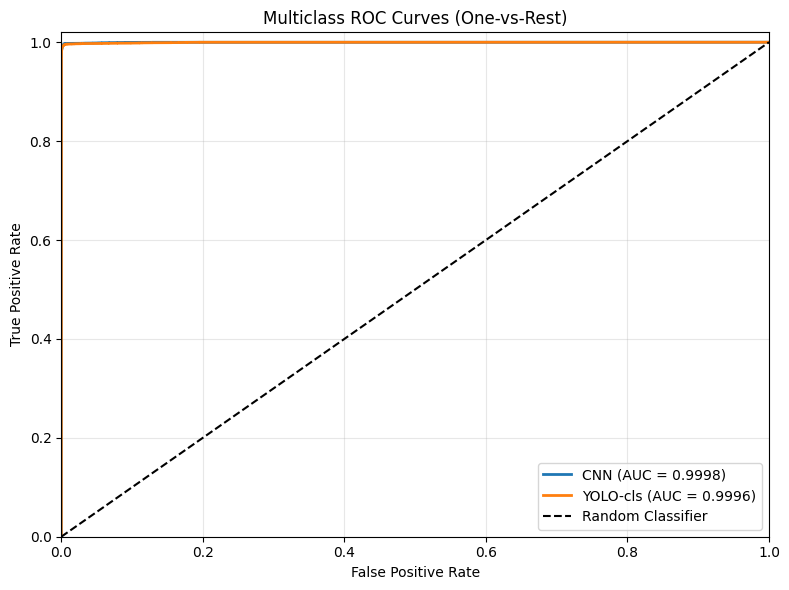

,Micro-average AUC,Macro-average AUC
Model,,
CNN,0.9998,0.9998
YOLO-cls,0.9996,0.9996


In [ ]:

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Convert true labels to one-hot representation
y_true_bin = label_binarize(
    y_true, classes=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(8, 6))

roc_results = []

# Calculate multiclass ROC-AUC for both models
for name, probs in clean_probs.items():

    # Micro-average ROC curve
    fpr, tpr, _ = roc_curve(
        y_true_bin.ravel(), probs.ravel()
    )

    micro_auc = auc(fpr, tpr)

    # Macro-average ROC-AUC
    macro_auc = roc_auc_score(
        y_true_bin, probs, average="macro"
    )

    plt.plot(
        fpr, tpr,
        linewidth=2,
        label=f"{name} (AUC = {micro_auc:.4f})"
    )

    roc_results.append({
        "Model": name,
        "Micro-average AUC": micro_auc,
        "Macro-average AUC": macro_auc
    })

# Random classifier reference line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves (One-vs-Rest)")
plt.xlim([0, 1])
plt.ylim([0, 1.02])
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/content/roc_curves.png", dpi=300)
plt.show()

# Display ROC-AUC results
roc_df = pd.DataFrame(roc_results).set_index("Model")
display(roc_df.round(4))

roc_df.to_csv("/content/roc_auc_results.csv")


**Note on ROC-AUC vs. accuracy.** Class columns of the probability matrices follow the class-ID order 0-42, matching `label_binarize(..., classes=np.arange(NUM_CLASSES))`. Micro-AUC pools all one-vs-rest decisions and macro-AUC averages the per-class AUCs. AUC is near 1.0 for both models because it only measures how well the predicted probabilities *rank* the true class above the other classes for each one-vs-rest problem, not whether the top-1 prediction is correct. Accuracy (about 97%) counts only the highest-probability class. A model can therefore have a very high AUC and still make top-1 errors, so AUC is much less discriminative than accuracy here and should not be used on its own to separate the two models.

**Clean Test Set: Per-Class Report**

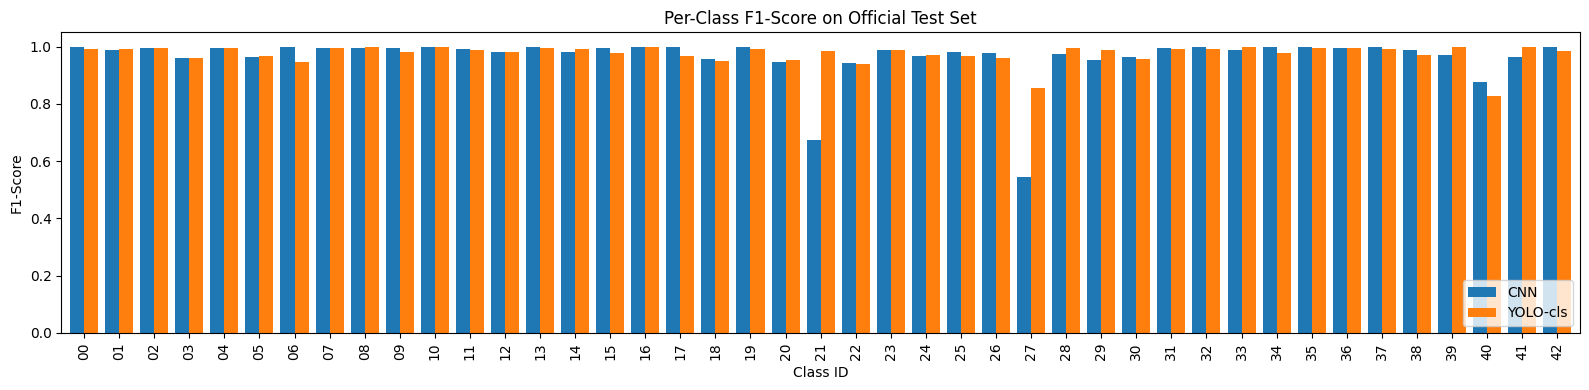


CNN: 10 lowest-F1 classes


,precision,recall,f1-score,support
27,0.600000,0.500000,0.545455,60.0
21,0.681818,0.666667,0.674157,90.0
40,0.817308,0.944444,0.876289,90.0
22,1.000000,0.891667,0.942731,120.0
20,0.900000,1.000000,0.947368,90.0
29,0.909091,1.000000,0.952381,90.0
18,0.997222,0.920513,0.957333,390.0
03,0.997608,0.926667,0.960829,450.0
30,0.986014,0.940000,0.962457,150.0
05,0.942424,0.987302,0.964341,630.0



YOLO-cls: 10 lowest-F1 classes


,precision,recall,f1-score,support
40,0.715447,0.977778,0.826291,90.0
27,0.756410,0.983333,0.855072,60.0
22,1.000000,0.883333,0.938053,120.0
06,0.992701,0.906667,0.947735,150.0
18,0.975610,0.923077,0.948617,390.0
20,0.909091,1.000000,0.952381,90.0
30,0.965986,0.946667,0.956229,150.0
26,0.945946,0.972222,0.958904,180.0
03,1.000000,0.926667,0.961938,450.0
05,0.941353,0.993651,0.966795,630.0



CNN: top-10 confusions (true -> predicted)


,True,Predicted,Count
0,03,05,32
1,27,21,28
2,18,27,17
3,21,12,15
4,14,29,9
5,22,25,9
6,12,40,7
7,21,20,6
8,18,28,6
9,38,40,6



YOLO-cls: top-10 confusions (true -> predicted)


,True,Predicted,Count
0,03,05,31
1,38,40,26
2,18,27,17
3,17,09,16
4,22,25,10
5,12,40,9
6,12,15,8
7,06,20,7
8,18,26,7
9,26,25,5


In [ ]:
per_class = {}
for name, probs in clean_probs.items():
    rep = classification_report(
        y_true, probs.argmax(1), labels=list(range(NUM_CLASSES)),
        target_names=class_names, output_dict=True, zero_division=0)
    per_class[name] = pd.DataFrame(rep).T.iloc[:NUM_CLASSES]

per_class_df = pd.concat(per_class, axis=1)   # columns: (model, metric)
per_class_df.to_csv("/content/per_class_metrics.csv")

# Per-class F1 comparison
f1_df = pd.DataFrame({n: per_class[n]["f1-score"] for n in per_class})
f1_df.plot(kind="bar", figsize=(16, 4), width=0.8)
plt.title("Per-Class F1-Score on Official Test Set")
plt.xlabel("Class ID")
plt.ylabel("F1-Score")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Lowest-scoring classes per model
for name in per_class:
    print(f"\n{name}: 10 lowest-F1 classes")
    display(per_class[name].sort_values("f1-score").head(10))

# Most frequent misclassifications per model
for name, probs in clean_probs.items():
    cm = confusion_matrix(y_true, probs.argmax(1), labels=range(NUM_CLASSES))
    np.fill_diagonal(cm, 0)
    top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:10], cm.shape))[0]
    print(f"\n{name}: top-10 confusions (true -> predicted)")
    display(pd.DataFrame(
        [(class_names[t], class_names[p], int(cm[t, p])) for t, p in top],
        columns=["True", "Predicted", "Count"]))

**Robustness Evaluation: Image Corruptions**

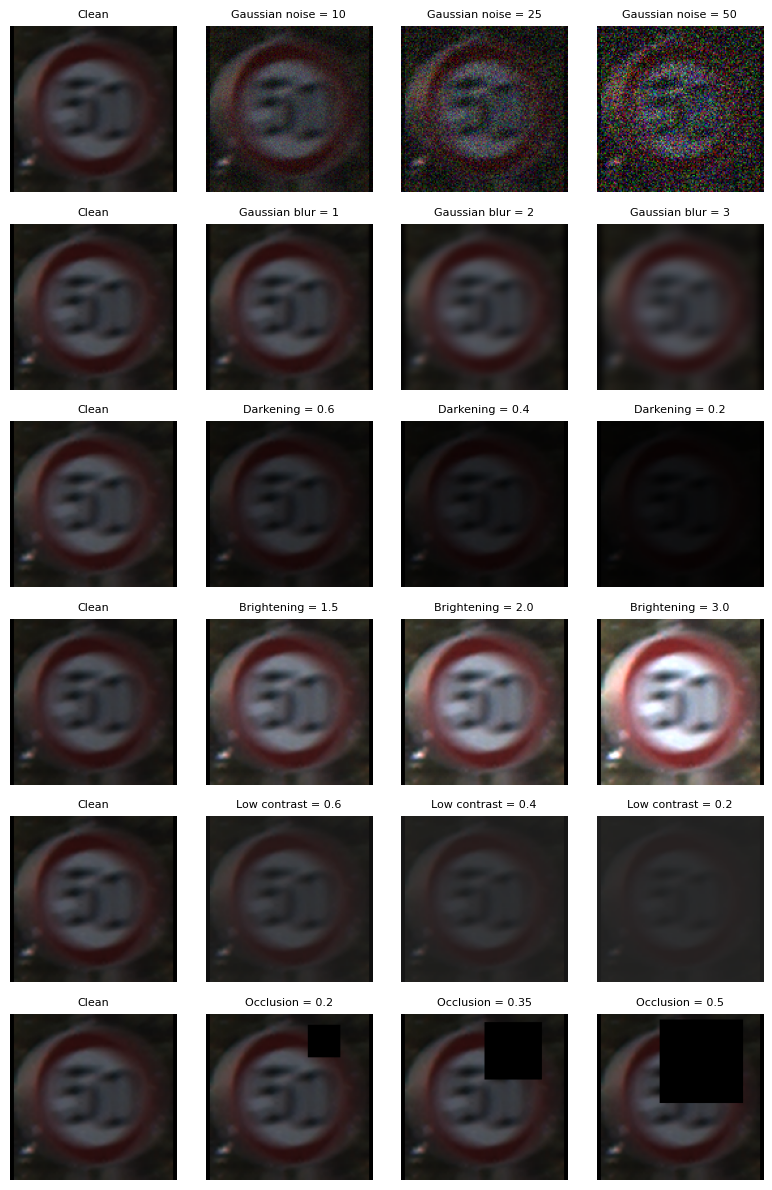

In [ ]:
def _chunked(fn, X, chunk=1024):
    return np.concatenate([fn(X[i:i + chunk]) for i in range(0, len(X), chunk)])

def gaussian_noise(X, sigma):
    rng = np.random.default_rng(SEED)
    def f(x):
        y = x.astype(np.float32) + rng.normal(0, sigma, x.shape).astype(np.float32)
        return np.clip(y, 0, 255).astype(np.uint8)
    return _chunked(f, X)

def gaussian_blur(X, radius):
    return np.stack([
        np.array(Image.fromarray(im).filter(ImageFilter.GaussianBlur(radius)))
        for im in X
    ])

def brightness(X, factor):
    return _chunked(
        lambda x: np.clip(x.astype(np.float32) * factor, 0, 255).astype(np.uint8), X)

def contrast(X, factor):
    def f(x):
        x = x.astype(np.float32)
        m = x.mean(axis=(1, 2, 3), keepdims=True)
        return np.clip((x - m) * factor + m, 0, 255).astype(np.uint8)
    return _chunked(f, X)

def occlusion(X, frac):
    """Black square placed inside the sign area, not on the letterbox padding."""
    rng = np.random.default_rng(SEED)
    side = int(IMG * frac)
    out = X.copy()
    for im in out:
        content = im.any(axis=2)                       # non-black pixels
        rows = np.where(content.any(axis=1))[0]
        cols = np.where(content.any(axis=0))[0]
        r0, r1 = (rows[0], rows[-1] + 1) if len(rows) else (0, IMG)
        c0, c1 = (cols[0], cols[-1] + 1) if len(cols) else (0, IMG)
        r = rng.integers(r0, max(r0, r1 - side) + 1)
        c = rng.integers(c0, max(c0, c1 - side) + 1)
        im[r:r + side, c:c + side] = 0
    return out

# corruption -> (function, [severity 1, 2, 3 parameters])
CORRUPTIONS = {
    "Gaussian noise (sigma)":  (gaussian_noise, [10, 25, 50]),
    "Gaussian blur (radius)":  (gaussian_blur,  [1, 2, 3]),
    "Darkening (factor)":      (brightness,     [0.6, 0.4, 0.2]),
    "Brightening (factor)":    (brightness,     [1.5, 2.0, 3.0]),
    "Low contrast (factor)":   (contrast,       [0.6, 0.4, 0.2]),
    "Occlusion (side frac.)":  (occlusion,      [0.2, 0.35, 0.5]),
}

# Quick visual of the corruptions on one test image
demo = X_test[1234:1235]
fig, axes = plt.subplots(len(CORRUPTIONS), 4, figsize=(8, 2 * len(CORRUPTIONS)))
for r, (cname, (fn, levels)) in enumerate(CORRUPTIONS.items()):
    axes[r, 0].imshow(demo[0]); axes[r, 0].set_title("Clean", fontsize=8)
    for s, lv in enumerate(levels, start=1):
        axes[r, s].imshow(fn(demo, lv)[0])
        axes[r, s].set_title(f"{cname.split(' (')[0]} = {lv}", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Robustness Evaluation: Run on Corrupted Test Set**

In [ ]:
# Set to an int (e.g., 5000) to evaluate a random subset and save time
N_ROBUST = None

if N_ROBUST:
    idx = np.random.default_rng(SEED).choice(len(X_test), N_ROBUST, replace=False)
    X_r, y_r = X_test[idx], y_true[idx]
else:
    X_r, y_r = X_test, y_true

clean_acc = {n: float((predict_fn(X_r).argmax(1) == y_r).mean())
             for n, predict_fn in MODELS.items()}

records = []
for cname, (fn, levels) in CORRUPTIONS.items():
    for severity, level in enumerate(levels, start=1):
        X_c = fn(X_r, level)
        for mname, predict_fn in MODELS.items():
            acc = float((predict_fn(X_c).argmax(1) == y_r).mean())
            records.append({
                "Corruption": cname, "Severity": severity, "Level": level,
                "Model": mname, "Accuracy": acc,
                "Clean Accuracy": clean_acc[mname],
                "Accuracy Drop": clean_acc[mname] - acc,
                "Retained (%)": acc / clean_acc[mname] * 100,
            })
        del X_c
        gc.collect()
        print(f"Done: {cname}, severity {severity}")

robust_df = pd.DataFrame(records)
robust_df.to_csv("/content/robustness_results.csv", index=False)

Done: Gaussian noise (sigma), severity 1
Done: Gaussian noise (sigma), severity 2
Done: Gaussian noise (sigma), severity 3
Done: Gaussian blur (radius), severity 1
Done: Gaussian blur (radius), severity 2
Done: Gaussian blur (radius), severity 3
Done: Darkening (factor), severity 1
Done: Darkening (factor), severity 2
Done: Darkening (factor), severity 3
Done: Brightening (factor), severity 1
Done: Brightening (factor), severity 2
Done: Brightening (factor), severity 3
Done: Low contrast (factor), severity 1
Done: Low contrast (factor), severity 2
Done: Low contrast (factor), severity 3
Done: Occlusion (side frac.), severity 1
Done: Occlusion (side frac.), severity 2
Done: Occlusion (side frac.), severity 3


**Robustness Evaluation: Results Table & Plots**

,Clean_Accuracy,Mean_Corrupted_Accuracy,Mean_Accuracy_Drop,Worst_Case_Accuracy,Mean_Retained_Pct
Model,,,,,
CNN,0.9817,0.8810,0.1007,0.3064,89.7456
YOLO-cls,0.9814,0.8679,0.1135,0.1906,88.4326


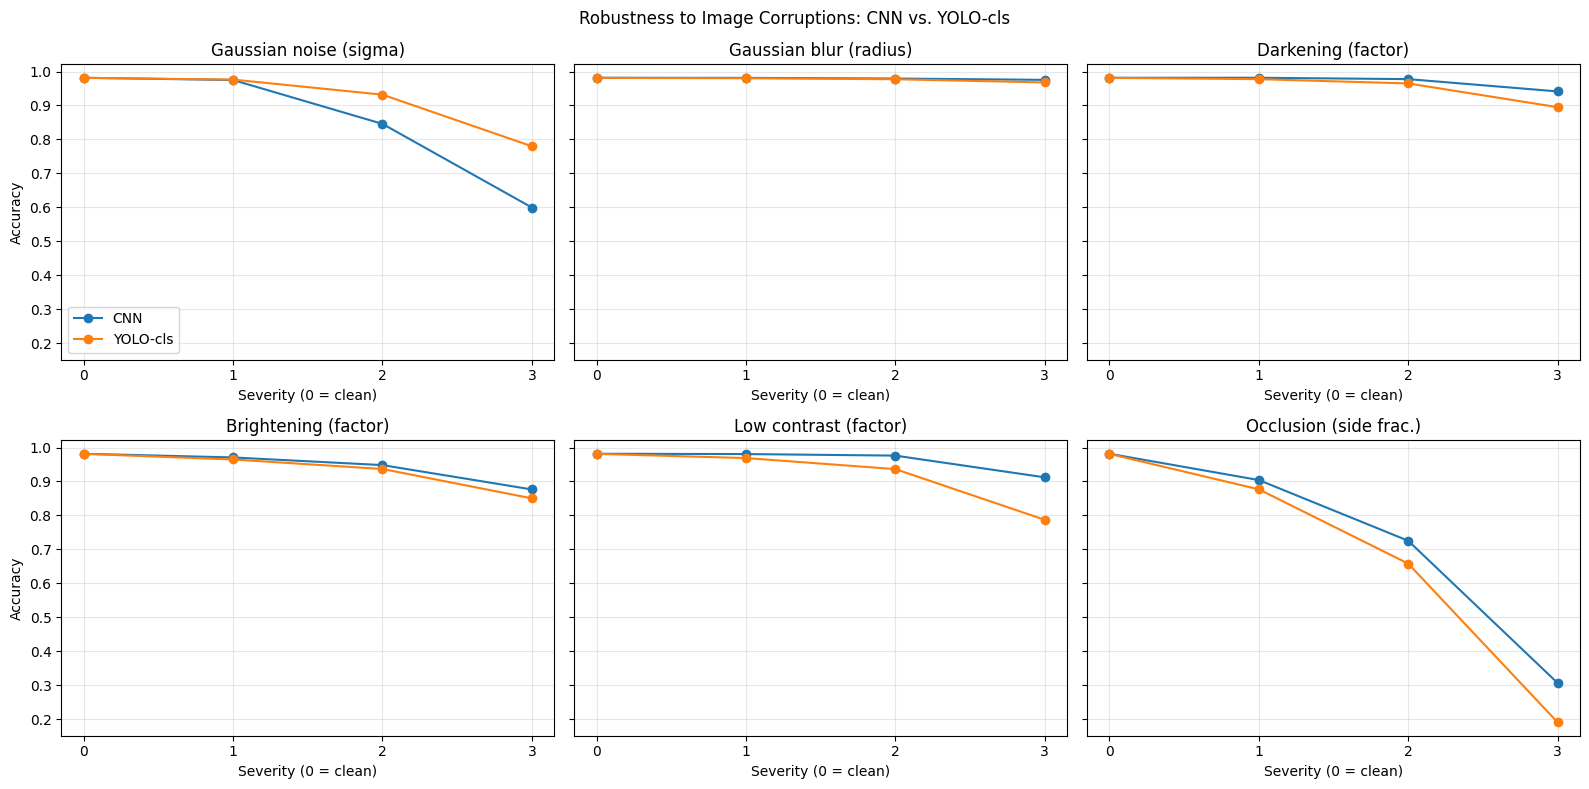

In [ ]:
# Pivot: accuracy per corruption/severity, one column per model
table = robust_df.pivot_table(
    index=["Corruption", "Severity", "Level"],
    columns="Model", values="Accuracy")
display(table.style.format("{:.4f}"))

# Mean accuracy across severities and overall robustness summary
summary = (robust_df.groupby("Model")
           .agg(Mean_Corrupted_Accuracy=("Accuracy", "mean"),
                Mean_Accuracy_Drop=("Accuracy Drop", "mean"),
                Worst_Case_Accuracy=("Accuracy", "min"),
                Mean_Retained_Pct=("Retained (%)", "mean")))
summary.insert(0, "Clean_Accuracy", pd.Series(clean_acc))
display(summary.style.format("{:.4f}"))
summary.to_csv("/content/robustness_summary.csv")

# Accuracy vs. severity (one panel per corruption)
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for ax, cname in zip(axes.flat, CORRUPTIONS):
    sub = robust_df[robust_df["Corruption"] == cname]
    for mname in MODELS:
        s = sub[sub["Model"] == mname].sort_values("Severity")
        ax.plot([0] + list(s["Severity"]), [clean_acc[mname]] + list(s["Accuracy"]),
                marker="o", label=mname)
    ax.set_title(cname)
    ax.set_xlabel("Severity (0 = clean)")
    ax.set_xticks([0, 1, 2, 3])
    ax.grid(True, alpha=0.3)
axes[0, 0].set_ylabel("Accuracy")
axes[1, 0].set_ylabel("Accuracy")
axes[0, 0].legend()
plt.suptitle("Robustness to Image Corruptions: CNN vs. YOLO-cls")
plt.tight_layout()
plt.show()

Misclassified classes

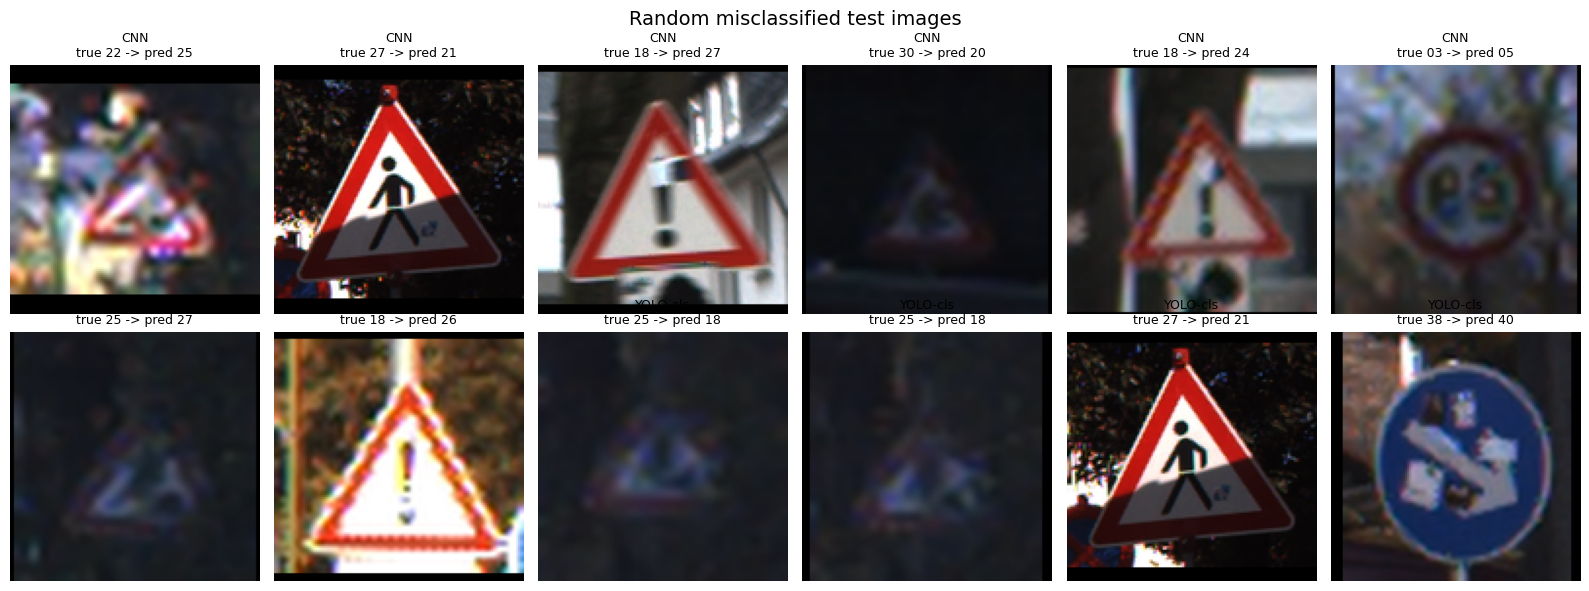

In [ ]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 6, figsize=(16, 6))

for row, (name, probs) in enumerate(clean_probs.items()):
    pred = probs.argmax(1)
    wrong = np.where(pred != y_true)[0]
    pick = rng.choice(wrong, size=min(6, len(wrong)), replace=False)
    for ax in axes[row]:
        ax.axis("off")
    for ax, i in zip(axes[row], pick):
        ax.imshow(X_test[i])
        ax.set_title(f"{name}\ntrue {class_names[y_true[i]]} -> pred {class_names[pred[i]]}", fontsize=9)

plt.suptitle("Random misclassified test images", fontsize=14)
plt.tight_layout()
plt.show()

**B.Analysis**

===== Original Test Accuracies =====
CNN Accuracy: 0.9817
YOLO Accuracy: 0.9814
Accuracy Difference (CNN - YOLO): 0.0003

Accuracy values match the shared evaluation.

===== Bootstrap Confidence Intervals =====


,Model,Accuracy / Difference,CI Lower,CI Upper
0,CNN,0.981710,0.979414,0.983927
1,YOLO-cls,0.981394,0.978939,0.983690
2,CNN - YOLO-cls,0.000317,-0.002375,0.003009



===== Bootstrap Interpretation =====
The 95% bootstrap confidence interval includes zero.
The interval does not exclude a zero accuracy difference.

===== Exact McNemar's Test =====
Both models correct: 12257
Both models wrong: 93
CNN correct, YOLO wrong: 142
YOLO correct, CNN wrong: 138
Discordant pairs: 280
P-value: 0.857755
No statistically significant difference detected (p >= 0.05).
This does not prove that the models are equivalent.


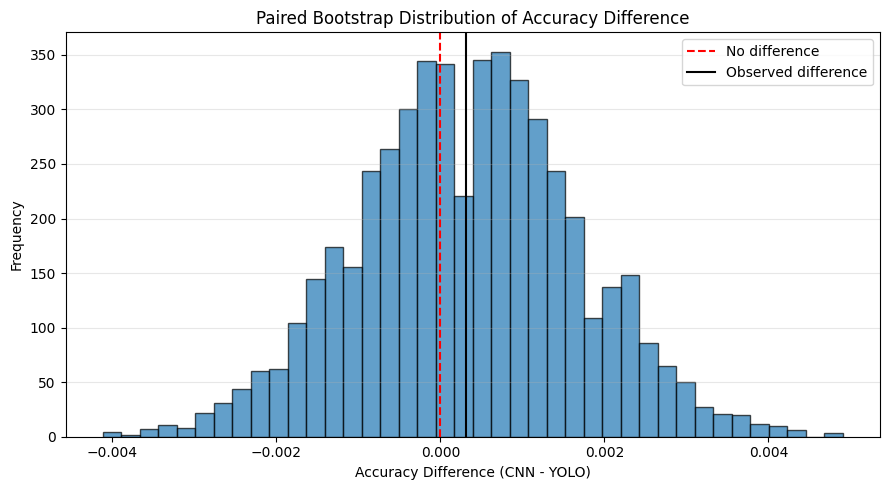

In [ ]:
# ============================================================
# STATISTICAL SIGNIFICANCE ANALYSIS
# Paired Bootstrap Confidence Intervals + Exact McNemar's Test
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import binomtest

# ------------------------------------------------------------
# 1. Retrieve predictions from the shared evaluation section
# ------------------------------------------------------------

cnn_probs = np.asarray(clean_probs["CNN"])
yolo_probs = np.asarray(clean_probs["YOLO-cls"])
y_true = np.asarray(y_true)

NUM_CLASSES = 43

# ------------------------------------------------------------
# 2. Validate prediction matrices and labels
# ------------------------------------------------------------

assert y_true.ndim == 1, "Test labels must be one-dimensional."

assert len(y_true) > 0, "Test set must not be empty."

assert np.issubdtype(y_true.dtype, np.integer), (
    "Test labels must contain integer class IDs."
)

assert np.all((y_true >= 0) & (y_true < NUM_CLASSES)), (
    "Test labels must be between 0 and 42."
)

assert cnn_probs.shape == (len(y_true), NUM_CLASSES), (
    "CNN predictions do not match the test labels."
)

assert yolo_probs.shape == (len(y_true), NUM_CLASSES), (
    "YOLO predictions do not match the test labels."
)

assert np.all(np.isfinite(cnn_probs)), (
    "CNN predictions contain invalid values."
)

assert np.all(np.isfinite(yolo_probs)), (
    "YOLO predictions contain invalid values."
)

# Both prediction matrices must correspond to the same
# ordered test images, as established in the shared
# evaluation section of the project.

# ------------------------------------------------------------
# 3. Calculate predictions and correctness
# ------------------------------------------------------------

cnn_pred = np.argmax(cnn_probs, axis=1)
yolo_pred = np.argmax(yolo_probs, axis=1)

cnn_correct = (cnn_pred == y_true)
yolo_correct = (yolo_pred == y_true)

cnn_accuracy = float(cnn_correct.mean())
yolo_accuracy = float(yolo_correct.mean())

accuracy_difference = cnn_accuracy - yolo_accuracy

print("===== Original Test Accuracies =====")

print(f"CNN Accuracy: {cnn_accuracy:.4f}")
print(f"YOLO Accuracy: {yolo_accuracy:.4f}")

print(
    f"Accuracy Difference (CNN - YOLO): "
    f"{accuracy_difference:.4f}"
)

# ------------------------------------------------------------
# 4. Check consistency with the shared comparison table
# ------------------------------------------------------------

assert np.isclose(
    cnn_accuracy,
    comparison_df.loc["CNN", "Top-1 Accuracy"]
), "CNN accuracy differs from the shared evaluation."

assert np.isclose(
    yolo_accuracy,
    comparison_df.loc["YOLO-cls", "Top-1 Accuracy"]
), "YOLO accuracy differs from the shared evaluation."

print("\nAccuracy values match the shared evaluation.")

# ------------------------------------------------------------
# 5. Paired Bootstrap Confidence Intervals
# ------------------------------------------------------------

B = 5000
rng = np.random.default_rng(42)

n = len(y_true)

cnn_bootstrap = np.empty(B)
yolo_bootstrap = np.empty(B)
difference_bootstrap = np.empty(B)

for i in range(B):

    # Same sampled test images for both models
    indices = rng.integers(0, n, size=n)

    cnn_acc = cnn_correct[indices].mean()
    yolo_acc = yolo_correct[indices].mean()

    cnn_bootstrap[i] = cnn_acc
    yolo_bootstrap[i] = yolo_acc

    difference_bootstrap[i] = cnn_acc - yolo_acc


def confidence_interval(values):
    return np.percentile(values, [2.5, 97.5])


cnn_ci = confidence_interval(cnn_bootstrap)
yolo_ci = confidence_interval(yolo_bootstrap)
difference_ci = confidence_interval(difference_bootstrap)

# ------------------------------------------------------------
# 6. Display and save bootstrap results
# ------------------------------------------------------------

results = pd.DataFrame({
    "Model": ["CNN", "YOLO-cls", "CNN - YOLO-cls"],
    "Accuracy / Difference": [
        cnn_accuracy,
        yolo_accuracy,
        accuracy_difference
    ],
    "CI Lower": [
        cnn_ci[0],
        yolo_ci[0],
        difference_ci[0]
    ],
    "CI Upper": [
        cnn_ci[1],
        yolo_ci[1],
        difference_ci[1]
    ]
})

print("\n===== Bootstrap Confidence Intervals =====")

display(results)

results.to_csv(
    "/content/gala_bootstrap_results.csv",
    index=False
)

# Check whether the difference CI includes zero
ci_includes_zero = (
    difference_ci[0] <= 0 <= difference_ci[1]
)

print("\n===== Bootstrap Interpretation =====")

if ci_includes_zero:
    print(
        "The 95% bootstrap confidence interval includes zero."
    )
    print(
        "The interval does not exclude a zero accuracy difference."
    )
else:
    print(
        "The 95% bootstrap confidence interval excludes zero."
    )

# ------------------------------------------------------------
# 7. Exact McNemar's Test
# ------------------------------------------------------------

cnn_only_correct = int(np.sum(
    cnn_correct & ~yolo_correct
))

yolo_only_correct = int(np.sum(
    ~cnn_correct & yolo_correct
))

both_correct = int(np.sum(
    cnn_correct & yolo_correct
))

both_wrong = int(np.sum(
    ~cnn_correct & ~yolo_correct
))

discordant = cnn_only_correct + yolo_only_correct

assert (
    both_correct
    + both_wrong
    + cnn_only_correct
    + yolo_only_correct
) == n

if discordant > 0:

    p_value = binomtest(
        cnn_only_correct,
        discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue

else:
    p_value = 1.0

print("\n===== Exact McNemar's Test =====")

print("Both models correct:", both_correct)
print("Both models wrong:", both_wrong)

print("CNN correct, YOLO wrong:", cnn_only_correct)
print("YOLO correct, CNN wrong:", yolo_only_correct)

print("Discordant pairs:", discordant)
print(f"P-value: {p_value:.6f}")

alpha = 0.05

if p_value < alpha:

    print(
        "Statistically significant difference detected "
        "(p < 0.05)."
    )

else:

    print(
        "No statistically significant difference detected "
        "(p >= 0.05)."
    )

    print(
        "This does not prove that the models are equivalent."
    )

# ------------------------------------------------------------
# 8. Save McNemar results
# ------------------------------------------------------------

mcnemar_df = pd.DataFrame([{
    "Both Correct": both_correct,
    "Both Wrong": both_wrong,
    "CNN Only Correct": cnn_only_correct,
    "YOLO Only Correct": yolo_only_correct,
    "Discordant Pairs": discordant,
    "P-value": p_value,
    "Significant at 0.05": p_value < alpha
}])

mcnemar_df.to_csv(
    "/content/gala_mcnemar_results.csv",
    index=False
)

# ------------------------------------------------------------
# 9. Visualization
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.hist(
    difference_bootstrap,
    bins=40,
    alpha=0.7,
    edgecolor="black"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="No difference"
)

plt.axvline(
    accuracy_difference,
    color="black",
    linestyle="-",
    label="Observed difference"
)

plt.xlabel("Accuracy Difference (CNN - YOLO)")
plt.ylabel("Frequency")

plt.title(
    "Paired Bootstrap Distribution of Accuracy Difference"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

All 43 GTSRB classes are correctly mapped.
Prediction arrays match the test labels.

===== Traffic Sign Family Analysis =====


,Family,Model,Samples,Correct Predictions,Accuracy,Errors,Error Rate
0,End of Restrictions,CNN,210,206,0.980952,4,0.019048
1,End of Restrictions,YOLO-cls,210,210,1.000000,0,0.000000
2,Mandatory,CNN,1770,1747,0.987006,23,0.012994
3,Mandatory,YOLO-cls,1770,1730,0.977401,40,0.022599
4,Priority / Stop / Yield,CNN,2100,2074,0.987619,26,0.012381
5,Priority / Stop / Yield,YOLO-cls,2100,2072,0.986667,28,0.013333
6,Prohibitory,CNN,1860,1858,0.998925,2,0.001075
7,Prohibitory,YOLO-cls,1860,1835,0.986559,25,0.013441
8,Speed Limit,CNN,4320,4264,0.987037,56,0.012963
9,Speed Limit,YOLO-cls,4320,4254,0.984722,66,0.015278



Family results match overall test accuracies.


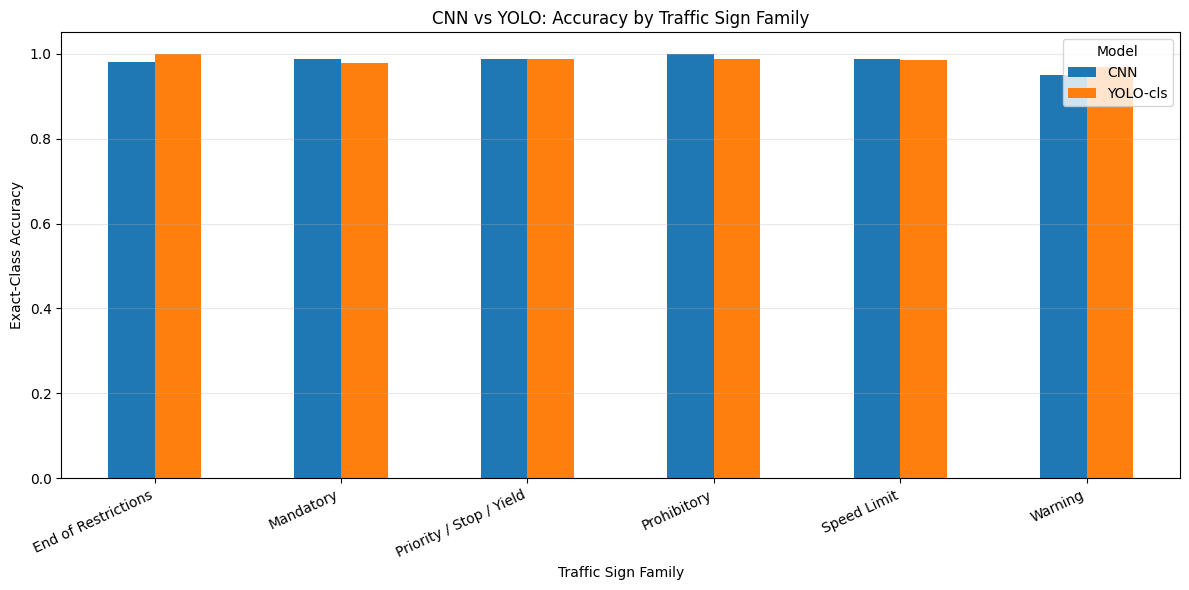

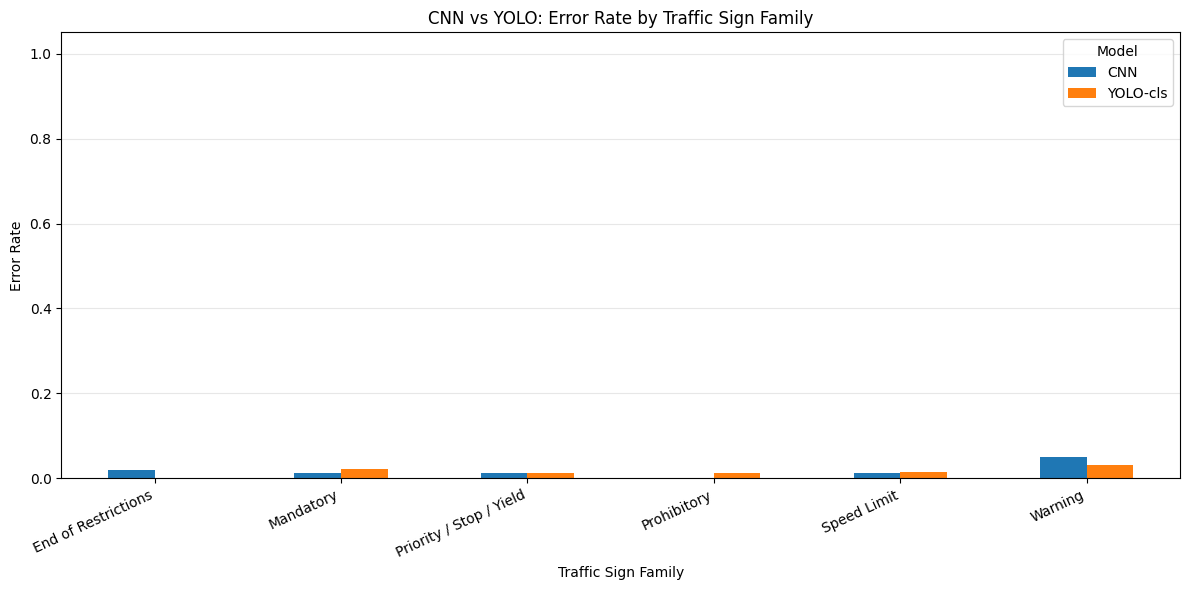

In [ ]:
# ============================================================
# TRAFFIC SIGN FAMILY ERROR ANALYSIS
# CNN vs YOLO Classification
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Define GTSRB Traffic Sign Families
# ------------------------------------------------------------

# Custom grouping based on the meanings of GTSRB classes.
# These groups are used for error analysis only.
# They are NOT official GTSRB families.
#
# Speed Limit includes class 6:
# End of 80 km/h speed limit.
#
# End of Restrictions includes:
# 32: End of all speed and passing limits
# 41: End of no passing
# 42: End of no passing by vehicles over 3.5 tons

family_map = {}

# Speed limit signs: Classes 0-8
for i in range(0, 9):
    family_map[i] = "Speed Limit"

# Prohibitory signs
for i in [9, 10, 15, 16, 17]:
    family_map[i] = "Prohibitory"

# Priority, yield and stop signs
for i in [11, 12, 13, 14]:
    family_map[i] = "Priority / Stop / Yield"

# Warning signs: Classes 18-31
for i in range(18, 32):
    family_map[i] = "Warning"

# End of restrictions
for i in [32, 41, 42]:
    family_map[i] = "End of Restrictions"

# Mandatory direction signs: Classes 33-40
for i in range(33, 41):
    family_map[i] = "Mandatory"

# ------------------------------------------------------------
# 2. Validate class mapping
# ------------------------------------------------------------

NUM_CLASSES = 43

assert set(family_map.keys()) == set(range(NUM_CLASSES)), (
    "All 43 GTSRB classes must be mapped exactly once."
)

assert len(family_map) == NUM_CLASSES

print("All 43 GTSRB classes are correctly mapped.")

# ------------------------------------------------------------
# 3. Validate test labels and predictions
# ------------------------------------------------------------

y_true = np.asarray(y_true)

predictions = {
    "CNN": np.asarray(cnn_pred),
    "YOLO-cls": np.asarray(yolo_pred)
}

assert y_true.ndim == 1
assert len(y_true) > 0

assert np.all((y_true >= 0) & (y_true < NUM_CLASSES))

for model_name, pred in predictions.items():

    assert pred.shape == y_true.shape, (
        f"{model_name} predictions do not match test labels."
    )

    assert np.all((pred >= 0) & (pred < NUM_CLASSES)), (
        f"{model_name} contains invalid class predictions."
    )

print("Prediction arrays match the test labels.")

# ------------------------------------------------------------
# 4. Assign each test image to a traffic sign family
# ------------------------------------------------------------

families = np.array([
    family_map[int(label)]
    for label in y_true
])

# ------------------------------------------------------------
# 5. Calculate family-level classification performance
# ------------------------------------------------------------

family_results = []

for family in sorted(np.unique(families)):

    mask = (families == family)

    total_samples = int(mask.sum())

    assert total_samples > 0, (
        f"Family {family} contains no test samples."
    )

    for model_name, pred in predictions.items():

        correct = int(np.sum(
            pred[mask] == y_true[mask]
        ))

        errors = int(np.sum(
            pred[mask] != y_true[mask]
        ))

        accuracy = correct / total_samples

        error_rate = errors / total_samples

        # Verify internal consistency
        assert correct + errors == total_samples

        assert np.isclose(
            accuracy + error_rate,
            1.0
        )

        family_results.append({
            "Family": family,
            "Model": model_name,
            "Samples": total_samples,
            "Correct Predictions": correct,
            "Accuracy": float(accuracy),
            "Errors": errors,
            "Error Rate": float(error_rate)
        })

# ------------------------------------------------------------
# 6. Display and save results
# ------------------------------------------------------------

family_df = pd.DataFrame(family_results)

print("\n===== Traffic Sign Family Analysis =====")

display(family_df)

family_df.to_csv(
    "/content/gala_family_error_analysis.csv",
    index=False
)

# ------------------------------------------------------------
# 7. Verify consistency with overall model accuracy
# ------------------------------------------------------------

for model_name, pred in predictions.items():

    subset = family_df[
        family_df["Model"] == model_name
    ]

    assert subset["Samples"].sum() == len(y_true)

    reconstructed_accuracy = (
        subset["Correct Predictions"].sum()
        / subset["Samples"].sum()
    )

    overall_accuracy = np.mean(pred == y_true)

    assert np.isclose(
        reconstructed_accuracy,
        overall_accuracy
    ), (
        f"{model_name} family results do not match "
        "overall accuracy."
    )

print("\nFamily results match overall test accuracies.")

# ------------------------------------------------------------
# 8. Visualization: Accuracy by Traffic Sign Family
# ------------------------------------------------------------

family_pivot = family_df.pivot(
    index="Family",
    columns="Model",
    values="Accuracy"
)

ax = family_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "CNN vs YOLO: Accuracy by Traffic Sign Family"
)

plt.ylabel("Exact-Class Accuracy")
plt.xlabel("Traffic Sign Family")

plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(title="Model")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Visualization: Error Rate by Traffic Sign Family
# ------------------------------------------------------------

ax = family_df.pivot(
    index="Family",
    columns="Model",
    values="Error Rate"
).plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "CNN vs YOLO: Error Rate by Traffic Sign Family"
)

plt.ylabel("Error Rate")
plt.xlabel("Traffic Sign Family")

plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(title="Model")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


===== Class-Wise Accuracy Analysis =====


,Model,Class ID,Test Samples,Correct Predictions,Class Accuracy
0,CNN,0,60,60,1.000000
1,CNN,1,720,719,0.998611
2,CNN,2,750,746,0.994667
3,CNN,3,450,417,0.926667
4,CNN,4,660,653,0.989394
...,...,...,...,...,...
81,YOLO-cls,38,690,656,0.950725
82,YOLO-cls,39,90,90,1.000000
83,YOLO-cls,40,90,88,0.977778
84,YOLO-cls,41,60,60,1.000000



Class-wise results match overall test accuracies.

===== Spearman Correlation Results =====


,Model,Spearman Rho,P-value,Number of Classes
0,CNN,-0.091394,0.559977,43
1,YOLO-cls,-0.250666,0.104955,43



Model: CNN
Spearman Rho: -0.0914
P-value: 0.5600
No statistically significant association was detected.

Model: YOLO-cls
Spearman Rho: -0.2507
P-value: 0.1050
No statistically significant association was detected.

Note: This analysis examines TEST class support, not training-set imbalance.


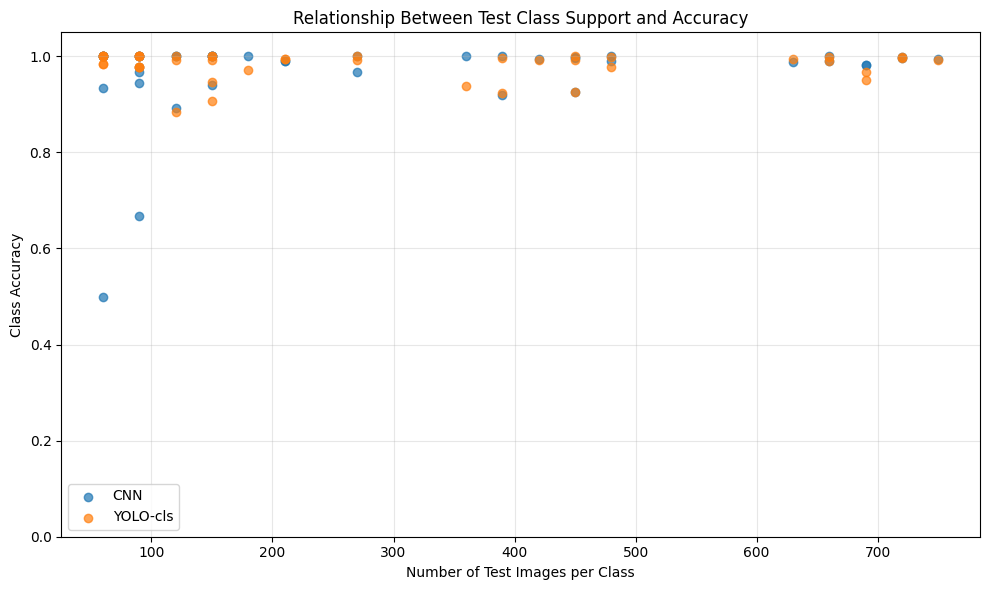

In [ ]:
# ============================================================
# CLASS-WISE TEST SUPPORT AND ACCURACY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr

# ------------------------------------------------------------
# 1. Calculate class-wise accuracy
# ------------------------------------------------------------

NUM_CLASSES = 43

class_results = []

for model_name, pred in predictions.items():

    for class_id in range(NUM_CLASSES):

        mask = (y_true == class_id)

        count = int(mask.sum())

        if count > 0:

            correct = int(np.sum(
                pred[mask] == y_true[mask]
            ))

            accuracy = correct / count

        else:

            correct = 0
            accuracy = np.nan

        class_results.append({
            "Model": model_name,
            "Class ID": class_id,
            "Test Samples": count,
            "Correct Predictions": correct,
            "Class Accuracy": accuracy
        })

# ------------------------------------------------------------
# 2. Display and save results
# ------------------------------------------------------------

class_df = pd.DataFrame(class_results)

print("\n===== Class-Wise Accuracy Analysis =====")

display(class_df)

class_df.to_csv(
    "/content/gala_class_support_accuracy.csv",
    index=False
)

# ------------------------------------------------------------
# 3. Validate class-wise results
# ------------------------------------------------------------

for model_name, pred in predictions.items():

    subset = class_df[
        class_df["Model"] == model_name
    ]

    assert len(subset) == NUM_CLASSES

    assert subset["Class ID"].nunique() == NUM_CLASSES

    assert subset["Test Samples"].sum() == len(y_true)

    reconstructed_accuracy = (
        subset["Correct Predictions"].sum()
        / subset["Test Samples"].sum()
    )

    overall_accuracy = np.mean(pred == y_true)

    assert np.isclose(
        reconstructed_accuracy,
        overall_accuracy
    ), (
        f"{model_name} class-wise accuracy does not "
        "match overall accuracy."
    )

print("\nClass-wise results match overall test accuracies.")

# ------------------------------------------------------------
# 4. Spearman Correlation Analysis
# ------------------------------------------------------------

# This examines the association between the number of
# TEST images per class and class-wise classification accuracy.
#
# It does NOT measure the effect of training-set imbalance.

correlation_results = []

for model_name in predictions.keys():

    subset = class_df[
        class_df["Model"] == model_name
    ].dropna(
        subset=["Class Accuracy"]
    )

    sample_counts = subset["Test Samples"]
    accuracies = subset["Class Accuracy"]

    # Spearman correlation requires variation
    # in both variables.

    if (
        len(subset) >= 3
        and sample_counts.nunique() > 1
        and accuracies.nunique() > 1
    ):

        correlation, p_value = spearmanr(
            sample_counts,
            accuracies
        )

    else:

        correlation = np.nan
        p_value = np.nan

    correlation_results.append({
        "Model": model_name,
        "Spearman Rho": correlation,
        "P-value": p_value,
        "Number of Classes": len(subset)
    })

# ------------------------------------------------------------
# 5. Display and save correlation results
# ------------------------------------------------------------

correlation_df = pd.DataFrame(correlation_results)

print("\n===== Spearman Correlation Results =====")

display(correlation_df)

correlation_df.to_csv(
    "/content/gala_test_support_correlation.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Interpret correlation results
# ------------------------------------------------------------

for _, row in correlation_df.iterrows():

    model_name = row["Model"]
    rho = row["Spearman Rho"]
    p_value = row["P-value"]

    print(f"\nModel: {model_name}")

    if np.isnan(rho) or np.isnan(p_value):

        print("Correlation could not be calculated.")

    else:

        print(f"Spearman Rho: {rho:.4f}")
        print(f"P-value: {p_value:.4f}")

        if p_value < 0.05:

            print(
                "A statistically significant association "
                "was detected."
            )

        else:

            print(
                "No statistically significant association "
                "was detected."
            )

print(
    "\nNote: This analysis examines TEST class support, "
    "not training-set imbalance."
)

# ------------------------------------------------------------
# 7. Visualization
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for model_name in predictions.keys():

    subset = class_df[
        class_df["Model"] == model_name
    ]

    plt.scatter(
        subset["Test Samples"],
        subset["Class Accuracy"],
        label=model_name,
        alpha=0.7
    )

plt.xlabel("Number of Test Images per Class")
plt.ylabel("Class Accuracy")

plt.title(
    "Relationship Between Test Class Support and Accuracy"
)

plt.ylim(0, 1.05)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Final Reproducibility and Consistency Checks

In [ ]:
# Final consistency checks: selected parameters, checkpoints, class count, and result sources.
from pathlib import Path
import numpy as np
assert Path("/content/best_cnn_tuned.keras").exists(), "Final tuned CNN checkpoint is missing."
assert Path("/content/best_yolo_cls_tuned.pt").exists(), "Final tuned YOLO checkpoint is missing."
assert len(cnn_search_results) == 8, "CNN search must contain 8 unique trials."
assert len(yolo_search_results) == 8, "YOLO search must contain 8 unique trials."
assert len(clean_probs["CNN"]) == len(y_true) == len(clean_probs["YOLO-cls"])
assert clean_probs["CNN"].shape[1] == clean_probs["YOLO-cls"].shape[1] == NUM_CLASSES
assert np.isclose(comparison_df.loc["CNN", "Top-1 Accuracy"], (clean_probs["CNN"].argmax(1) == y_true).mean())
assert np.isclose(comparison_df.loc["YOLO-cls", "Top-1 Accuracy"], (clean_probs["YOLO-cls"].argmax(1) == y_true).mean())
print("PASS: Both tuned checkpoints exist; both search logs contain 8 trials; shared test predictions and comparison metrics are consistent.")
print("CNN selected parameters:", best_cnn_params)
print("YOLO selected parameters:", yolo_best)


PASS: Both tuned checkpoints exist; both search logs contain 8 trials; shared test predictions and comparison metrics are consistent.
CNN selected parameters: {'learning_rate': 0.001, 'optimizer': 'Adam', 'weight_decay': 0.0005, 'dropout': 0.2}
YOLO selected parameters: {'lr0': 0.003, 'optimizer': 'AdamW', 'weight_decay': 0.0, 'dropout': 0.2}


Robustness data validation passed.

===== Robustness AUC Results =====


,Corruption,Model,Robustness AUC,Clean Accuracy,AUC Drop
0,Brightening (factor),CNN,0.949433,0.981710,0.032278
1,Brightening (factor),YOLO-cls,0.939179,0.981394,0.042214
2,Darkening (factor),CNN,0.973661,0.981710,0.008050
3,Darkening (factor),YOLO-cls,0.960280,0.981394,0.021114
4,Gaussian blur (radius),CNN,0.979810,0.981710,0.001900
5,Gaussian blur (radius),YOLO-cls,0.977435,0.981394,0.003959
6,Gaussian noise (sigma),CNN,0.870494,0.981710,0.111217
7,Gaussian noise (sigma),YOLO-cls,0.929625,0.981394,0.051768
8,Low contrast (factor),CNN,0.968026,0.981710,0.013684
9,Low contrast (factor),YOLO-cls,0.929942,0.981394,0.051452



AUC results are complete and internally consistent.

===== Average Robustness AUC =====


,Robustness AUC,AUC Drop
Model,,
CNN,0.916557,0.065154
YOLO-cls,0.907242,0.074151



===== Robustness AUC Interpretation =====
CNN Average AUC: 0.916557
YOLO Average AUC: 0.907242
AUC Difference (CNN - YOLO): 0.009314
CNN has a higher average robustness AUC under the selected corruption settings.

Note: These results are descriptive and do not establish statistical significance.


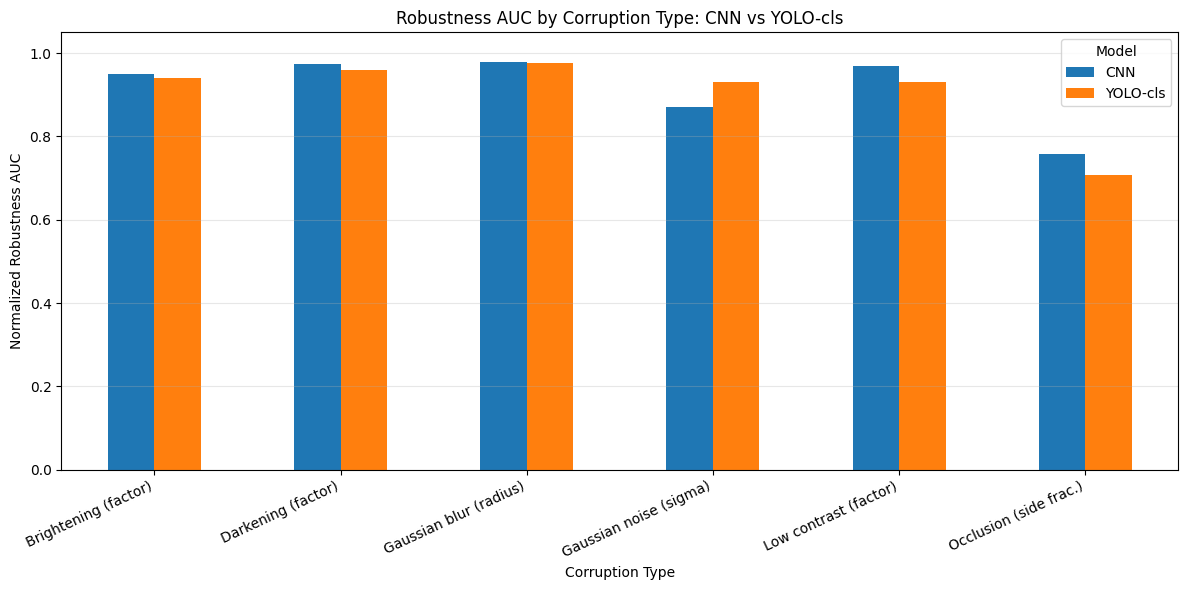

In [ ]:
# ============================================================
# ROBUSTNESS AREA UNDER THE CURVE (AUC)
# CNN vs YOLO Classification
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Validate robustness evaluation results
# ------------------------------------------------------------

required_columns = {
    "Corruption",
    "Severity",
    "Model",
    "Accuracy",
    "Clean Accuracy"
}

assert required_columns.issubset(robust_df.columns), (
    "robust_df is missing required columns."
)

assert not robust_df.empty, (
    "Robustness results must not be empty."
)

expected_models = {"CNN", "YOLO-cls"}

assert set(robust_df["Model"]) == expected_models, (
    "Expected CNN and YOLO-cls robustness results."
)

# Verify that the robustness results include every
# corruption type defined in the shared evaluation.

expected_corruptions = set(CORRUPTIONS.keys())

assert set(robust_df["Corruption"]) == expected_corruptions, (
    "Robustness results do not match the defined corruptions."
)

# Check for missing or invalid accuracy values.

for column in ["Accuracy", "Clean Accuracy"]:

    values = robust_df[column].to_numpy(dtype=float)

    assert np.all(np.isfinite(values)), (
        f"{column} contains invalid values."
    )

    assert np.all((values >= 0) & (values <= 1)), (
        f"{column} must contain values between 0 and 1."
    )

print("Robustness data validation passed.")

# ------------------------------------------------------------
# 2. Calculate Robustness AUC for each corruption and model
# ------------------------------------------------------------

auc_results = []

for (corruption, model), group in robust_df.groupby(
    ["Corruption", "Model"]
):

    group = group.sort_values("Severity")

    # Each model must have exactly three severity levels.
    # This also prevents duplicate severity entries.

    assert group["Severity"].tolist() == [1, 2, 3], (
        f"Invalid severity levels for {corruption}, {model}."
    )

    # Verify consistent clean accuracy within each group.

    clean_values = group[
        "Clean Accuracy"
    ].to_numpy(dtype=float)

    assert np.allclose(
        clean_values,
        clean_values[0]
    ), (
        f"Inconsistent clean accuracy for {model}."
    )

    clean_accuracy = float(clean_values[0])

    # Include clean accuracy at severity 0.

    severities = np.array(
        [0, 1, 2, 3],
        dtype=float
    )

    accuracies = np.concatenate([
        [clean_accuracy],
        group["Accuracy"].to_numpy(dtype=float)
    ])

    # --------------------------------------------------------
    # Normalized AUC using trapezoidal integration
    # --------------------------------------------------------

    # Severity levels are treated as equally spaced.
    #
    # This AUC summarizes accuracy across the selected
    # corruption settings. It is not a universal
    # robustness measure.

    auc = float(
        np.trapezoid(
            accuracies,
            severities
        ) / (severities[-1] - severities[0])
    )

    # Difference between clean accuracy and average
    # accuracy represented by the robustness curve.

    auc_drop = clean_accuracy - auc

    # Verify the normalized AUC is within [0, 1].

    assert 0 <= auc <= 1, (
        f"Invalid AUC for {corruption}, {model}."
    )

    auc_results.append({
        "Corruption": corruption,
        "Model": model,
        "Robustness AUC": auc,
        "Clean Accuracy": clean_accuracy,
        "AUC Drop": auc_drop
    })

# ------------------------------------------------------------
# 3. Display and save AUC results
# ------------------------------------------------------------

auc_df = pd.DataFrame(auc_results)

print("\n===== Robustness AUC Results =====")

display(auc_df)

auc_df.to_csv(
    "/content/gala_robustness_auc.csv",
    index=False
)

# ------------------------------------------------------------
# 4. Validate completeness and consistency
# ------------------------------------------------------------

expected_rows = (
    len(expected_corruptions)
    * len(expected_models)
)

assert len(auc_df) == expected_rows, (
    "Missing or duplicated corruption-model results."
)

# Each model must have results for every corruption type.

for model_name in expected_models:

    subset = auc_df[
        auc_df["Model"] == model_name
    ]

    assert set(subset["Corruption"]) == expected_corruptions, (
        f"Missing corruption results for {model_name}."
    )

    assert len(subset) == len(expected_corruptions)

    # Clean accuracy should be identical across
    # corruption types for the same model.

    assert np.allclose(
        subset["Clean Accuracy"],
        subset["Clean Accuracy"].iloc[0]
    ), (
        f"Inconsistent clean accuracy for {model_name}."
    )

print("\nAUC results are complete and internally consistent.")

# ------------------------------------------------------------
# 5. Calculate average Robustness AUC for each model
# ------------------------------------------------------------

summary_auc = auc_df.groupby("Model")[
    ["Robustness AUC", "AUC Drop"]
].mean()

print("\n===== Average Robustness AUC =====")

display(summary_auc)

summary_auc.to_csv(
    "/content/gala_robustness_auc_summary.csv"
)

# ------------------------------------------------------------
# 6. Descriptive interpretation
# ------------------------------------------------------------

print("\n===== Robustness AUC Interpretation =====")

cnn_auc = float(
    summary_auc.loc["CNN", "Robustness AUC"]
)

yolo_auc = float(
    summary_auc.loc["YOLO-cls", "Robustness AUC"]
)

auc_difference = cnn_auc - yolo_auc

print(f"CNN Average AUC: {cnn_auc:.6f}")
print(f"YOLO Average AUC: {yolo_auc:.6f}")

print(
    f"AUC Difference (CNN - YOLO): "
    f"{auc_difference:.6f}"
)

if np.isclose(cnn_auc, yolo_auc, atol=1e-4):

    print(
        "The models have very similar average "
        "robustness AUC values."
    )

elif cnn_auc > yolo_auc:

    print(
        "CNN has a higher average robustness AUC "
        "under the selected corruption settings."
    )

else:

    print(
        "YOLO-cls has a higher average robustness AUC "
        "under the selected corruption settings."
    )

print(
    "\nNote: These results are descriptive and do not "
    "establish statistical significance."
)

# ------------------------------------------------------------
# 7. Visualization: CNN vs YOLO Robustness AUC
# ------------------------------------------------------------

auc_pivot = auc_df.pivot(
    index="Corruption",
    columns="Model",
    values="Robustness AUC"
)

ax = auc_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Robustness AUC by Corruption Type: CNN vs YOLO-cls"
)

plt.ylabel("Normalized Robustness AUC")
plt.xlabel("Corruption Type")

plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(title="Model")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

===== Shared Model Comparison =====


,Top-1 Accuracy,Inference (ms/img),Parameters
Model,,,
CNN,0.981710,0.561739,11208171
YOLO-cls,0.981394,0.613390,1586187



Comparison accuracies match the statistical significance analysis.

===== Model Comparison Summary =====


,Metric,CNN,YOLO-cls,CNN - YOLO
0,Top-1 Accuracy,9.817102e-01,9.813935e-01,3.167063e-04
1,Inference (ms/img),5.617388e-01,6.133903e-01,-5.165156e-02
2,Parameters,1.120817e+07,1.586187e+06,9.621984e+06



===== Comparison Fairness Audit =====


,Factor,Status,Explanation
0,Test Dataset,Matched in shared evaluation,Both models are evaluated on the same GTSRB te...
1,Ground Truth Labels,Matched in shared evaluation,Both models are compared against the same grou...
2,Evaluation Metric,Matched,Both models are evaluated using Top-1 classifi...
3,Image Preprocessing,Different pipelines,CNN and YOLO-cls use model-specific preprocess...
4,Model Parameters,Reported,"Parameter counts are available, but counting c..."
5,Final Training Time,Reported; not identical compute budget,Final CNN and YOLO training use their selected...
6,Hyperparameter Search,Matched search protocol; architecture-specific...,Both models use coordinate search with 8 uniqu...
7,Inference Time,Pipeline-specific estimate,"Use the shared test images and report warm-up,..."



===== Model Comparison Interpretation =====
CNN Accuracy: 0.981710
YOLO Accuracy: 0.981394
Accuracy Difference (CNN - YOLO): 0.000317
CNN has higher observed test accuracy.
CNN has lower reported inference time.
YOLO-cls has fewer reported parameters.

Note: Observed accuracy differences should be interpreted alongside the paired statistical tests.
Inference-time comparisons are descriptive and depend on the measurement methodology.
Matched test data and metrics support a controlled evaluation comparison, but do not establish identical training conditions.


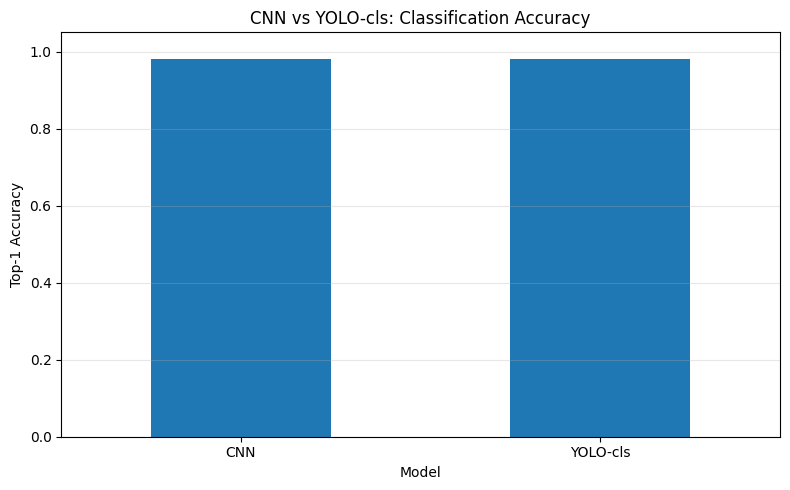

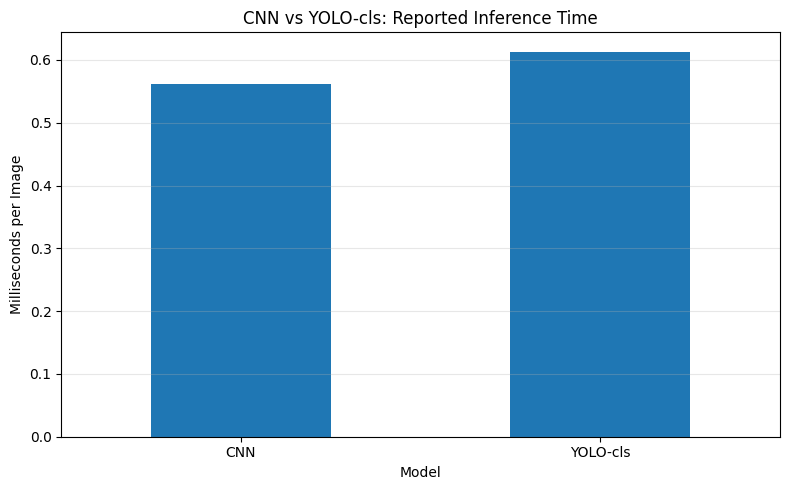

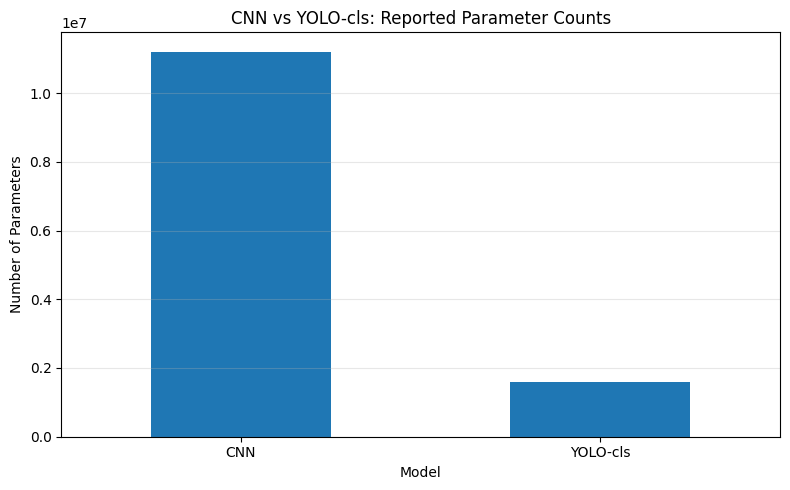

In [ ]:
# ============================================================
# MODEL COMPARISON AND FAIRNESS ASSESSMENT
# CNN vs YOLO Classification
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Retrieve shared model comparison results
# ------------------------------------------------------------

required_cols = [
    "Top-1 Accuracy",
    "Inference (ms/img)",
    "Parameters"
]

required_models = ["CNN", "YOLO-cls"]

assert all(
    col in comparison_df.columns
    for col in required_cols
), "Missing required comparison columns."

assert all(
    model in comparison_df.index
    for model in required_models
), "Missing CNN or YOLO-cls results."

assert comparison_df.index.is_unique, (
    "Model names in comparison_df must be unique."
)

# Create a separate copy to avoid modifying
# the shared evaluation results.

gala_comparison_df = comparison_df.loc[
    required_models,
    required_cols
].copy()

# ------------------------------------------------------------
# 2. Validate comparison metrics
# ------------------------------------------------------------

for column in required_cols:

    values = pd.to_numeric(
        gala_comparison_df[column],
        errors="raise"
    ).to_numpy(dtype=float)

    assert np.all(np.isfinite(values)), (
        f"{column} contains invalid values."
    )

accuracy_values = gala_comparison_df[
    "Top-1 Accuracy"
].to_numpy(dtype=float)

inference_values = gala_comparison_df[
    "Inference (ms/img)"
].to_numpy(dtype=float)

parameter_values = gala_comparison_df[
    "Parameters"
].to_numpy(dtype=float)

assert np.all(
    (accuracy_values >= 0) &
    (accuracy_values <= 1)
), "Accuracy values must be between 0 and 1."

assert np.all(inference_values > 0), (
    "Inference times must be positive."
)

assert np.all(parameter_values > 0), (
    "Parameter counts must be positive."
)

print("===== Shared Model Comparison =====")

display(gala_comparison_df)

# ------------------------------------------------------------
# 3. Verify consistency with statistical analysis
# ------------------------------------------------------------

assert np.isclose(
    gala_comparison_df.loc["CNN", "Top-1 Accuracy"],
    cnn_accuracy
), "CNN accuracy differs from statistical analysis."

assert np.isclose(
    gala_comparison_df.loc["YOLO-cls", "Top-1 Accuracy"],
    yolo_accuracy
), "YOLO accuracy differs from statistical analysis."

print(
    "\nComparison accuracies match the statistical "
    "significance analysis."
)

# ------------------------------------------------------------
# 4. Calculate descriptive model differences
# ------------------------------------------------------------

cnn_acc = float(
    gala_comparison_df.loc["CNN", "Top-1 Accuracy"]
)

yolo_acc = float(
    gala_comparison_df.loc["YOLO-cls", "Top-1 Accuracy"]
)

cnn_time = float(
    gala_comparison_df.loc["CNN", "Inference (ms/img)"]
)

yolo_time = float(
    gala_comparison_df.loc["YOLO-cls", "Inference (ms/img)"]
)

cnn_params = float(
    gala_comparison_df.loc["CNN", "Parameters"]
)

yolo_params = float(
    gala_comparison_df.loc["YOLO-cls", "Parameters"]
)

comparison_summary = pd.DataFrame([
    {
        "Metric": "Top-1 Accuracy",
        "CNN": cnn_acc,
        "YOLO-cls": yolo_acc,
        "CNN - YOLO": cnn_acc - yolo_acc
    },
    {
        "Metric": "Inference (ms/img)",
        "CNN": cnn_time,
        "YOLO-cls": yolo_time,
        "CNN - YOLO": cnn_time - yolo_time
    },
    {
        "Metric": "Parameters",
        "CNN": cnn_params,
        "YOLO-cls": yolo_params,
        "CNN - YOLO": cnn_params - yolo_params
    }
])

print("\n===== Model Comparison Summary =====")

display(comparison_summary)

comparison_summary.to_csv(
    "/content/gala_model_comparison_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 5. Comparison Fairness Audit
# ------------------------------------------------------------

# The audit distinguishes matched evaluation conditions
# from model-specific differences and factors that
# require additional verification.

fairness_audit = pd.DataFrame([
    {
        "Factor": "Test Dataset",
        "Status": "Matched in shared evaluation",
        "Explanation":
            "Both models are evaluated on the same "
            "GTSRB test examples. Prediction ordering "
            "must be preserved by the shared evaluation."
    },
    {
        "Factor": "Ground Truth Labels",
        "Status": "Matched in shared evaluation",
        "Explanation":
            "Both models are compared against the "
            "same ground-truth labels."
    },
    {
        "Factor": "Evaluation Metric",
        "Status": "Matched",
        "Explanation":
            "Both models are evaluated using "
            "Top-1 classification accuracy."
    },
    {
        "Factor": "Image Preprocessing",
        "Status": "Different pipelines",
        "Explanation":
            "CNN and YOLO-cls use model-specific "
            "preprocessing pipelines."
    },
    {
        "Factor": "Model Parameters",
        "Status": "Reported",
        "Explanation":
            "Parameter counts are available, but "
            "counting conventions may differ between "
            "model frameworks or representations."
    },
    {
        "Factor": "Final Training Time",
        "Status": "Reported; not identical compute budget",
        "Explanation":
            "Final CNN and YOLO training use their selected settings and "
            "full development data, but their architectures and stopping "
            "rules differ. Report measured times; do not claim identical compute."
    },
    {
        "Factor": "Hyperparameter Search",
        "Status": "Matched search protocol; architecture-specific compute",
        "Explanation":
            "Both models use coordinate search with 8 unique trials, "
            "25% stratified train/validation subsets, 4 search epochs, "
            "and batch size 64. CNN search uses 64x64 inputs to match "
            "YOLO imgsz=64. Per-trial compute can still differ by architecture. "
            "Final full-data retraining budgets also differ (CNN epoch cap vs YOLO time cap)."
    },
    {
        "Factor": "Inference Time",
        "Status": "Pipeline-specific estimate",
        "Explanation":
            "Use the shared test images and report warm-up, batch size, "
            "device synchronization, and whether preprocessing is included. "
            "Treat timing as implementation-specific."
    }
])

print("\n===== Comparison Fairness Audit =====")

display(fairness_audit)

fairness_audit.to_csv(
    "/content/gala_fairness_audit.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Descriptive interpretation
# ------------------------------------------------------------

print("\n===== Model Comparison Interpretation =====")

print(
    f"CNN Accuracy: {cnn_acc:.6f}"
)

print(
    f"YOLO Accuracy: {yolo_acc:.6f}"
)

print(
    f"Accuracy Difference (CNN - YOLO): "
    f"{cnn_acc - yolo_acc:.6f}"
)

if cnn_acc > yolo_acc:

    print("CNN has higher observed test accuracy.")

elif yolo_acc > cnn_acc:

    print("YOLO-cls has higher observed test accuracy.")

else:

    print("Both models have equal observed test accuracy.")

if cnn_time < yolo_time:

    print("CNN has lower reported inference time.")

elif yolo_time < cnn_time:

    print("YOLO-cls has lower reported inference time.")

else:

    print("Both models have equal reported inference time.")

if cnn_params < yolo_params:

    print("CNN has fewer reported parameters.")

elif yolo_params < cnn_params:

    print("YOLO-cls has fewer reported parameters.")

else:

    print("Both models have equal reported parameter counts.")

print(
    "\nNote: Observed accuracy differences should be "
    "interpreted alongside the paired statistical tests."
)

print(
    "Inference-time comparisons are descriptive and "
    "depend on the measurement methodology."
)

print(
    "Matched test data and metrics support a "
    "controlled evaluation comparison, but do not "
    "establish identical training conditions."
)

# ------------------------------------------------------------
# 7. Visualization: Classification Accuracy
# ------------------------------------------------------------

ax = gala_comparison_df[
    "Top-1 Accuracy"
].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title(
    "CNN vs YOLO-cls: Classification Accuracy"
)

plt.ylabel("Top-1 Accuracy")
plt.xlabel("Model")

plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Visualization: Inference Time
# ------------------------------------------------------------

ax = gala_comparison_df[
    "Inference (ms/img)"
].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title(
    "CNN vs YOLO-cls: Reported Inference Time"
)

plt.ylabel("Milliseconds per Image")
plt.xlabel("Model")

plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Visualization: Model Parameters
# ------------------------------------------------------------

ax = gala_comparison_df[
    "Parameters"
].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title(
    "CNN vs YOLO-cls: Reported Parameter Counts"
)

plt.ylabel("Number of Parameters")
plt.xlabel("Model")

plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import zipfile
from pathlib import Path
from google.colab import files

root = Path("/content")
zip_path = root / "GTSRB_Final_Results.zip"

extensions = {".keras", ".pt", ".csv", ".png", ".jpg",
              ".pdf", ".json", ".npy", ".npz"}

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in root.iterdir():
        if file.is_file() and file.suffix.lower() in extensions:
            z.write(file, file.name)

    for folder in ["rfe_results"]:
        for file in (root / folder).rglob("*"):
            if file.is_file():
                z.write(file, file.relative_to(root))

print("All selected results saved successfully!")
files.download(str(zip_path))

All selected results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>